# Cascading Delays: What Actually Makes U.S. Flights Late
### CSI 2810 progress submission: Sameer Alshamiri and Jayden Nguyen

When a flight is late, the Bureau of Transportation Statistics (BTS) requires the airline to split the delay into five causes. The biggest of these, **late-arriving aircraft**, just means the plane showed up late from its previous flight, so it doesn't tell you where the delay actually started. Since every BTS record includes the aircraft's **tail number**, we can put each plane's flights for the day back in order and measure how delay carries from one flight to the next.

**Research questions**

* **Q1. Decomposition:** what share of delay minutes comes from carrier, weather, air traffic system (NAS), security, and late-arriving aircraft, and how does the mix vary by carrier, airport and month?
* **Q2. Prediction:** can we predict whether a flight departs 15+ minutes late using only information available about two hours before scheduled departure?
* **Q3. Propagation:** given an aircraft's first delay of the day, how much carries into its later flights, and how fast does it fade?

**Data:** BTS Reporting Carrier On-Time Performance, January to December 2025: 12 monthly files, 7,001,619 scheduled flights, 14 carriers, 352 airports.

### What this notebook covers (mapped to the progress rubric)

| Section | Contents | Rubric item |
|---|---|---|
| **1. Data wrangling** | loading 12 months, type conversions, missing values, consistency checks, outliers, rebuilding aircraft rotations, feature creation, saving the clean table | Data wrangling (30) |
| **2. Exploratory data analysis** | six exploratory questions, descriptive statistics, 11 figures with interpretation | EDA (30) |
| **3. Preliminary modeling** | goal, time-based split, two baselines, logistic regression, PR-AUC and precision/recall, leakage audit, next steps | Preliminary modeling (20) |
| **4. Progress summary** | written summary (1-2 pages): progress made, challenges, plans for the final | Documentation (20) |

**How to run:** copy `config.example.py` to `config.py` and set `DATA_DIR` to your copy of the shared data folder (the one containing `raw/` and `processed/`), then run all cells top to bottom. It takes about 2 minutes on a laptop with 16 GB RAM once the raw CSVs are on local disk. If Google Drive for desktop still has to download the 1.2 GB of CSVs, the first cell of Section 1 takes several minutes longer; marking `raw/bts` as *Available offline* in Drive avoids that. Package versions are in `requirements.txt`. The notebook reads only `raw/bts/`, writes the cleaned table to `processed/` and the figures to `figures/`. All random steps use `SEED = 42`, so the output is reproducible. Helper functions are in `src/` (`load`, `clean`, `rotations`, `features`, `evaluate`, `viz`), and each one has a docstring.

## 0. Setup

Imports, the random seed, and paths. `DATA_DIR` comes from each teammate's own `config.py` (gitignored; copy `config.example.py`), so no path is hard-coded in the notebook. Shared plot styling lives in `src/viz.py`.

In [1]:
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, precision_recall_curve
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

NOTEBOOK_START = time.time()

# Locate the repository root (the folder that holds src/ and config.py) so the
# notebook runs the same whether Jupyter was started in the repo or in notebooks/.
ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from config import DATA_DIR                    # each teammate's own path
from src import clean, evaluate, features, load, rotations, viz

SEED = 42                                      # every random step below uses this seed
np.random.seed(SEED)

DATA_DIR = Path(DATA_DIR)
RAW_DIR = DATA_DIR / "raw" / "bts"             # monthly CSVs, never modified
PROCESSED_DIR = DATA_DIR / "processed"         # cleaned output goes here
FIG_DIR = ROOT / "figures"                     # PNGs for the summary and slides
PROCESSED_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)
viz.set_style()

CARRIER_NAMES = {
    "AA": "American", "AS": "Alaska", "B6": "JetBlue", "DL": "Delta", "F9": "Frontier",
    "G4": "Allegiant", "HA": "Hawaiian", "MQ": "Envoy", "NK": "Spirit", "OH": "PSA",
    "OO": "SkyWest", "UA": "United", "WN": "Southwest", "YX": "Republic",
}
CAUSE_LABELS = {
    "CARRIER_DELAY": "Carrier",
    "WEATHER_DELAY": "Weather",
    "NAS_DELAY": "NAS (air traffic system)",
    "SECURITY_DELAY": "Security",
    "LATE_AIRCRAFT_DELAY": "Late-arriving aircraft",
}
MONTH_NAMES = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

print(f"pandas {pd.__version__} | numpy {np.__version__} | scikit-learn {sklearn.__version__} "
      f"| seaborn {sns.__version__}")

pandas 3.1.0 | numpy 2.5.4 | scikit-learn 1.9.1 | seaborn 0.13.2


# 1. Data wrangling

**Goal:** turn twelve raw monthly CSVs into one clean, typed, validated table of 2025 flights, rebuild each aircraft's daily sequence of flights, and create the features the rest of the project needs. For each step we explain what we checked and what we decided. Raw files are never modified; the result is saved to `processed/`.

## 1.1 Load the twelve monthly files

We downloaded the BTS *Reporting Carrier On-Time Performance* table for each month of 2025 (reporting carrier, so each flight is credited to the airline that physically flew it). Two loading decisions:

* **File names are inconsistent** (`TransStatsJUNE2025.csv` vs `TransStatsJUN...`, and August arrived as `TransStatsAUG2025.csv.csv`). Rather than renaming raw files, `load.find_month_files` reads the month name from each file name, and `load.load_year` then checks that every file really contains only that month.
* **Memory.** At default types the year would take several GB. We read only the 30 columns we use (the three destination ID columns duplicate `DEST`) and give every column an explicit compact type: text columns with few distinct values (carrier, airport, tail number) become `category`, numbers become 8 to 32-bit. Delay and flag columns must stay `float` at this stage because they contain blanks.

In [2]:
raw, file_log = load.load_year(RAW_DIR)
print(f"\nLoaded {len(raw):,} flights x {raw.shape[1]} columns "
      f"({raw.memory_usage(deep=True).sum() / 1e6:,.0f} MB in memory).")
print("Columns skipped at load:", load.DROP_COLS)
file_log

  loaded TransStatsJAN2025.csv          539,747 rows


  loaded TransStatsFEB2025.csv          504,884 rows


  loaded TransStatsMAR2025.csv          600,872 rows


  loaded TransStatsAPR2025.csv          583,950 rows


  loaded TransStatsMAY2025.csv          605,648 rows


  loaded TransStatsJUNE2025.csv         611,575 rows


... (4 outputs left out)

  loaded TransStatsNOV2025.csv          570,550 rows


  loaded TransStatsDEC2025.csv          582,304 rows



Loaded 7,001,619 flights x 30 columns (574 MB in memory).
Columns skipped at load: ['DEST_AIRPORT_ID', 'DEST_AIRPORT_SEQ_ID', 'DEST_CITY_MARKET_ID']


,month,file,size_mb,rows
0,1,TransStatsJAN2025.csv,88.5,539747
1,2,TransStatsFEB2025.csv,83.2,504884
2,3,TransStatsMAR2025.csv,98.9,600872
3,4,TransStatsAPR2025.csv,96.2,583950
4,5,TransStatsMAY2025.csv,100.2,605648
5,6,TransStatsJUNE2025.csv,101.7,611575
6,7,TransStatsJUL2025.csv,105.0,631428
7,8,TransStatsAUG2025.csv.csv,99.5,602378
8,9,TransStatsSEP2025.csv,92.3,562439
9,10,TransStatsOCT2025.csv,101.1,605844


**What we see.** All twelve files load with an identical 33-column layout (30 kept), **7,001,619 scheduled flights** in about 575 MB, a small fraction of what default types would need. Monthly volume runs from 504,884 flights in February to 631,428 in July. January's 539,747 rows match our earlier January-only exploration exactly, which confirms the loader reads the files the same way.

## 1.2 First look: types, missing values, flight status

In [3]:
raw.head(3).T

,0,1,2
YEAR,2025,2025,2025
MONTH,1,1,1
DAY_OF_MONTH,1,1,1
DAY_OF_WEEK,3,3,3
FL_DATE,1/1/2025 12:00:00 AM,1/1/2025 12:00:00 AM,1/1/2025 12:00:00 AM
OP_UNIQUE_CARRIER,AA,AA,AA
TAIL_NUM,N101NN,N101NN,N102UW
OP_CARRIER_FL_NUM,164,76,3244
ORIGIN,SFO,JFK,SAT
ORIGIN_STATE_ABR,CA,NY,TX


In [4]:
missing = pd.DataFrame({
    "missing values": raw.isna().sum(),
    "% of rows": raw.isna().mean().mul(100).round(2),
}).query("`missing values` > 0").sort_values("missing values", ascending=False)

status = pd.DataFrame({"flights": {
    "scheduled": len(raw),
    "cancelled": int((raw.CANCELLED == 1).sum()),
    "diverted": int((raw.DIVERTED == 1).sum()),
    "completed": int(((raw.CANCELLED == 0) & (raw.DIVERTED == 0)).sum()),
}})
status["% of scheduled"] = (status.flights / len(raw) * 100).round(2)
display(missing)
display(status)

,missing values,% of rows
CANCELLATION_CODE,6898743,98.53
CARRIER_DELAY,5466981,78.08
WEATHER_DELAY,5466981,78.08
NAS_DELAY,5466981,78.08
SECURITY_DELAY,5466981,78.08
LATE_AIRCRAFT_DELAY,5466981,78.08
ARR_DELAY,122135,1.74
ARR_DEL15,122135,1.74
DEP_DELAY,98591,1.41
DEP_DELAY_NEW,98591,1.41


,flights,% of scheduled
scheduled,7001619,100.00
cancelled,102876,1.47
diverted,19258,0.28
completed,6879485,98.26


**What we see.**
* The raw table needs work. Dates are text, flags are floats, and `CRS_DEP_TIME` is a number like `835` rather than a time.
* Missing values are concentrated in a few columns and look **structural rather than random**:
  * `CANCELLATION_CODE` is blank for the 98.5% of flights that were not cancelled.
  * The five cause columns are blank for 78% of flights, which is about the share that did not arrive 15+ minutes late.
  * The delay columns are blank for roughly the number of cancelled or diverted flights.
* Only 1.47% of 2025 flights were cancelled. That is half of January's 3.0%, so January was an unusually disrupted month.

Section 1.5 tests whether this structure holds row by row.

## 1.3 Type conversions

* **`FL_DATE`** is text like `"1/1/2025 12:00:00 AM"` (the midnight time is meaningless). We parse it with an explicit format and cross-check it against `YEAR`, `MONTH` and `DAY_OF_MONTH`.
* **Flags** (`CANCELLED`, `DIVERTED`, `DEP_DEL15`, `ARR_DEL15`) load as floats. `CANCELLED` and `DIVERTED` are never blank, so they become plain integers. `DEP_DEL15` is blank for cancelled flights and `ARR_DEL15` for cancelled or diverted ones; they become pandas' nullable `Int8`, so "unknown" stays different from 0.
* **Airports:** `ORIGIN` and `DEST` get the same category list so one leg's destination can be compared directly with the next leg's origin.

In [5]:
df = raw.copy()        # all cleaning happens on this copy; the raw CSVs are never touched

df, date_mismatches = clean.parse_flight_date(df)
df = clean.convert_flags(df)
df = clean.unify_airport_categories(df)

print("FL_DATE:", df.FL_DATE.dtype, "|", df.FL_DATE.min().date(), "to", df.FL_DATE.max().date(),
      "|", df.FL_DATE.nunique(), "distinct days")
print("Rows where the parsed date disagrees with YEAR/MONTH/DAY_OF_MONTH:", date_mismatches)
print("\nFlag columns after conversion:")
print(df[["CANCELLED", "DIVERTED", "DEP_DEL15", "ARR_DEL15"]].dtypes.to_string())

FL_DATE: datetime64[us] | 2025-01-01 to 2025-12-31 | 365 distinct days
Rows where the parsed date disagrees with YEAR/MONTH/DAY_OF_MONTH: 0

Flag columns after conversion:
CANCELLED    int8
DIVERTED     int8
DEP_DEL15    Int8
ARR_DEL15    Int8


**Tail numbers.** Our January exploration found thousands of tail numbers that do not start with `N` (every US-registered aircraft's registration does) and left this open. Checking the full year:

In [6]:
tail_labels = df.TAIL_NUM.cat.categories
non_n_tails = tail_labels[~tail_labels.str.startswith("N")]
non_n_rows = df.TAIL_NUM.isin(non_n_tails)

print(f"Tails not starting with 'N': {len(non_n_tails)} aircraft, {non_n_rows.sum():,} flights")
print("Carriers they belong to:",
      df.loc[non_n_rows, "OP_UNIQUE_CARRIER"].value_counts().loc[lambda s: s > 0].to_dict())
print("Allegiant (G4) flights whose tail does start with 'N':",
      int(((df.OP_UNIQUE_CARRIER == "G4") & df.TAIL_NUM.notna() & ~non_n_rows).sum()))
print("Examples:", list(non_n_tails[:6]))
print("Would adding 'N' collide with an existing tail?",
      any(("N" + t) in set(tail_labels) for t in non_n_tails))

df, n_fixed = clean.standardize_tails(df)
print(f"\nStandardized {n_fixed} Allegiant tail numbers (e.g. 812NV -> N812NV).")

Tails not starting with 'N': 137 aircraft, 130,370 flights
Carriers they belong to: {'G4': 130370}
Allegiant (G4) flights whose tail does start with 'N': 0
Examples: ['188NV', '189NV', '190NV', '191NV', '192NV', '193NV']


Would adding 'N' collide with an existing tail? False

Standardized 137 Allegiant tail numbers (e.g. 812NV -> N812NV).


**Result.** This answers the question we left open in January:
* Every tail number without the `N` prefix belongs to **Allegiant (G4)**: 137 aircraft, 130,370 flights.
* Allegiant never reports the prefix.
* Adding it creates no duplicates.

We standardize all of them to the FAA format. Rotations are keyed on carrier + tail + date, so this does not change any rotation, but it keeps tails comparable across carriers.

## 1.4 Scheduled times: from HHMM numbers to timestamps

`CRS_DEP_TIME` and `CRS_ARR_TIME` are clock times stored as numbers (`835` = 08:35, leading zeros dropped). Three complications:

1. **`2400`** means midnight at the *end* of the day. We convert HHMM to minutes after midnight and let 2400 become 1440 so it sorts after 23:59.
2. **Every time is local to its airport**, and BTS gives no time zones. We recover the clock difference between the two airports from the identity *arrival = departure + scheduled elapsed time + clock shift*. For a correct record that shift is a whole number of hours, which lets us put each arrival on the right calendar day: a red-eye lands the next morning, while a 07:00 departure from Atlanta (Eastern) can land at 06:50 the *same* day in Birmingham (Central).
3. **The International Date Line.** Guam and Saipan are 20 hours ahead of Honolulu, outside the plus or minus 12 hour range the identity can see, so Honolulu-Guam flights get an explicit one-day correction (`clean.DATELINE_AIRPORTS`).

The identity only works if the scheduled duration is right, so we first fix impossible durations: missing, zero or negative, or implying a gate-to-gate speed below 30 mph or above 650 mph. Those are replaced with the median duration of the same route.

In [7]:
df = clean.fix_scheduled_elapsed(df)
fixed = df.index[df.elapsed_imputed]
print(f"Scheduled durations replaced with the route median: {len(fixed)}")
raw.loc[fixed, ["OP_UNIQUE_CARRIER", "ORIGIN", "DEST", "CRS_DEP_TIME", "CRS_ARR_TIME",
                "CRS_ELAPSED_TIME", "DISTANCE"]].assign(
    implied_mph=lambda d: (d.DISTANCE / (d.CRS_ELAPSED_TIME / 60)).round(0),
    new_elapsed=df.loc[fixed, "CRS_ELAPSED_TIME"],
).head(8)

Scheduled durations replaced with the route median: 27


,OP_UNIQUE_CARRIER,ORIGIN,DEST,CRS_DEP_TIME,CRS_ARR_TIME,CRS_ELAPSED_TIME,DISTANCE,implied_mph,new_elapsed
188917,OO,DVL,JMS,1155,1352,177.0,83.0,28.0,52.0
563678,NK,LAX,RNO,1140,1018,1358.0,391.0,17.0,95.0
581793,NK,LAX,RNO,1150,1018,1348.0,391.0,17.0,95.0
820072,YX,SAV,LGA,800,809,9.0,722.0,4813.0,130.0
1184468,OH,CLT,TYS,2249,2259,10.0,177.0,1062.0,70.0
1615367,OH,CLT,TYS,2249,2359,1510.0,177.0,7.0,70.0
2948006,OO,ORD,MKE,1330,1625,175.0,67.0,23.0,60.0
3351940,HA,HNL,OGG,1305,1350,NaN,100.0,NaN,43.0


In [8]:
df = clean.add_schedule_times(df)
print(f"Arrivals landing on the next calendar day: {df.overnight.sum():,} ({df.overnight.mean():.1%})")
print(f"Records whose times imply a clock shift that is not whole hours: {df.schedule_inconsistent.sum()}")

shift_hours = (df.tz_shift_min / 60).value_counts().rename("flights")
shift_hours.index.name = "destination clock minus origin clock (hours)"
display(shift_hours.head(15).to_frame().T)

examples = pd.concat([
    df[df.overnight & (df.ORIGIN == "LAX") & (df.DEST == "JFK")].head(1),
    df[(df.ORIGIN == "ATL") & (df.DEST == "BHM")].head(1),
    df[df.CRS_DEP_TIME == 2400].head(1),
    df[(df.ORIGIN == "HNL") & (df.DEST == "GUM")].head(1),
    df[(df.ORIGIN == "GUM") & (df.DEST == "HNL")].head(1),
])
examples[["ORIGIN", "DEST", "FL_DATE", "CRS_DEP_TIME", "CRS_ARR_TIME", "CRS_ELAPSED_TIME",
          "tz_shift_min", "sched_dep", "sched_arr"]]

Arrivals landing on the next calendar day: 227,724 (3.3%)
Records whose times imply a clock shift that is not whole hours: 133


destination clock minus origin clock (hours),0.0,1.0,-1.0,2.0,-2.0,-3.0,3.0,4.0,-4.0,-5.0,5.0,6.0,-6.0,20.0,-20.0
flights,3514212,1120114,1119994,370278,370140,246280,246120,3402,3290,2224,2222,1241,1239,365,365


,ORIGIN,DEST,FL_DATE,CRS_DEP_TIME,CRS_ARR_TIME,CRS_ELAPSED_TIME,tz_shift_min,sched_dep,sched_arr
22,LAX,JFK,2025-01-01,2329,759,330.0,180.0,2025-01-01 23:29:00,2025-01-02 07:59:00
5414,ATL,BHM,2025-01-01,1630,1624,54.0,-60.0,2025-01-01 16:30:00,2025-01-01 16:24:00
3925582,DSM,ORD,2025-07-24,2400,145,105.0,0.0,2025-07-25 00:00:00,2025-07-25 01:45:00
11108,HNL,GUM,2025-01-01,1515,1900,465.0,1200.0,2025-01-01 15:15:00,2025-01-02 19:00:00
11172,GUM,HNL,2025-01-01,725,1840,435.0,-1200.0,2025-01-01 07:25:00,2024-12-31 18:40:00


**What we see.**
* **27 impossible durations** (for example, Savannah to New York in 9 minutes, Los Angeles to Reno in 22 hours) were replaced with the route's median.
* **The clock-shift identity works.** Nearly every flight's implied shift is a whole number of hours (0 for same-zone flights, plus or minus 1 to 6 for cross-country and Hawaii, plus or minus 20 for the date-line flights to Guam). Only **133 records** (0.002%) imply a fractional shift. Those are small clerical mismatches between time fields, so we flag and keep them.
* **227,724 flights (3.3%) land the next calendar day.**

The example table checks the tricky cases by hand:
* a Los Angeles red-eye lands at 07:59 the next morning
* the Atlanta to Birmingham flight lands six minutes "before" it left, in local time, on the same day
* the 2400 departure is placed at midnight of the following day
* Honolulu to Guam lands a calendar day later, and Guam to Honolulu a calendar day *earlier*

## 1.5 Missing values

Most blanks in this table are **structural**: they mean "does not apply", not "unknown". We verify that for the full year rather than assume it.

In [9]:
cancelled = df.CANCELLED == 1
diverted = df.DIVERTED == 1
completed = ~cancelled & ~diverted

structure = pd.DataFrame([
    ("DEP_DELAY blank", df.DEP_DELAY.isna().sum()),
    ("   ...of which the flight was cancelled", (df.DEP_DELAY.isna() & cancelled).sum()),
    ("cancelled flights that do have a DEP_DELAY (cancelled after pushback)",
     (cancelled & df.DEP_DELAY.notna()).sum()),
    ("ARR_DELAY blank", df.ARR_DELAY.isna().sum()),
    ("   ...of which the flight was cancelled or diverted", (df.ARR_DELAY.isna() & ~completed).sum()),
    ("   ...of which the flight completed normally (unexplained)", (df.ARR_DELAY.isna() & completed).sum()),
    ("TAIL_NUM blank", df.TAIL_NUM.isna().sum()),
    ("   ...of which the flight was cancelled", (df.TAIL_NUM.isna() & cancelled).sum()),
], columns=["", "rows"]).set_index("")
display(structure)
df.loc[df.ARR_DELAY.isna() & completed,
       ["FL_DATE", "OP_UNIQUE_CARRIER", "OP_CARRIER_FL_NUM", "ORIGIN", "DEST",
        "DEP_DELAY", "ARR_DELAY", "ARR_DEL15", "CANCELLED", "DIVERTED"]]

,rows
,
DEP_DELAY blank,98591
...of which the flight was cancelled,98591
cancelled flights that do have a DEP_DELAY (cancelled after pushback),4285
ARR_DELAY blank,122135
...of which the flight was cancelled or diverted,122134
...of which the flight completed normally (unexplained),1
TAIL_NUM blank,12501
...of which the flight was cancelled,12501


,FL_DATE,OP_UNIQUE_CARRIER,OP_CARRIER_FL_NUM,ORIGIN,DEST,DEP_DELAY,ARR_DELAY,ARR_DEL15,CANCELLED,DIVERTED
4789156,2025-09-06,YX,5859,JFK,MVY,0.0,NaN,<NA>,0,0


**Delay-cause columns.** BTS only asks airlines to split a delay into causes when the flight *arrived* 15 or more minutes late. Cross-tabulating arrival status against whether the five cause columns are blank shows whether that rule holds everywhere:

In [10]:
late_arr = df.ARR_DEL15.eq(1).fillna(False).to_numpy(dtype=bool)
arrival_status = pd.Series(np.select(
    [cancelled.to_numpy(), diverted.to_numpy(), df.ARR_DEL15.isna().to_numpy(), late_arr],
    ["cancelled", "diverted", "arrival time unknown", "arrived 15+ min late"],
    default="arrived < 15 min late",
), index=df.index, name="arrival status")

def cause_table():
    blank = df[clean.CAUSE_COLS].isna().all(axis=1).map({True: "causes blank", False: "causes filled"})
    return pd.crosstab(arrival_status, blank.rename(""))

print("Before filling:")
display(cause_table())

df = clean.fill_cause_columns(df)
print("After filling on-time arrivals with 0 and blanking zero-cause late arrivals:")
display(cause_table())
print(f"Late arrivals reporting 0 minutes for every cause (marked unattributed): "
      f"{df.cause_unattributed.sum()}")
df.loc[df.cause_unattributed, ["FL_DATE", "OP_UNIQUE_CARRIER", "ORIGIN", "DEST", "ARR_DELAY"]
       + clean.CAUSE_COLS].head(6)

Before filling:


,causes blank,causes filled
arrival status,,
arrival time unknown,1,0
arrived 15+ min late,0,1534638
arrived < 15 min late,5344846,0
cancelled,102876,0
diverted,19258,0


After filling on-time arrivals with 0 and blanking zero-cause late arrivals:


,causes blank,causes filled
arrival status,,
arrival time unknown,1,0
arrived 15+ min late,14,1534624
arrived < 15 min late,0,5344846
cancelled,102876,0
diverted,19258,0


Late arrivals reporting 0 minutes for every cause (marked unattributed): 14


,FL_DATE,OP_UNIQUE_CARRIER,ORIGIN,DEST,ARR_DELAY,CARRIER_DELAY,WEATHER_DELAY,NAS_DELAY,SECURITY_DELAY,LATE_AIRCRAFT_DELAY
4826255,2025-09-08,WN,FLL,BWI,75.0,NaN,NaN,NaN,NaN,NaN
5791226,2025-10-28,WN,ABQ,DEN,99.0,NaN,NaN,NaN,NaN,NaN
5830598,2025-10-30,WN,LAS,SAN,198.0,NaN,NaN,NaN,NaN,NaN
6166132,2025-11-17,WN,LAS,BUR,189.0,NaN,NaN,NaN,NaN,NaN
6183995,2025-11-18,WN,SMF,ONT,130.0,NaN,NaN,NaN,NaN,NaN
6184782,2025-11-18,WN,DEN,HOU,98.0,NaN,NaN,NaN,NaN,NaN


**Decisions on missing values**

| Column | Blank when | Decision |
|---|---|---|
| `DEP_DELAY`, `DEP_DEL15` | the flight was cancelled before pushback (all 98,591 blanks) | keep blank; cancelled flights are excluded from delay analysis and modeling |
| `ARR_DELAY`, `ARR_DEL15` | the flight was cancelled or diverted (122,134), plus **one** completed Republic flight (JFK to MVY, Sept 6) with no arrival time | keep blank; that single flight still counts for departure analyses |
| five cause columns | the flight arrived < 15 min late (by BTS design), or was cancelled or diverted | **fill with 0** for completed on-time arrivals, since their true cause minutes are zero; keep blank for cancelled and diverted flights |
| cause columns, 14 Southwest late arrivals | reported 0 minutes in every cause despite arriving 75 to 820 minutes late | set to blank and flag `cause_unattributed`; excluded from cause shares |
| `TAIL_NUM` | the flight was cancelled (all 12,501) | keep blank; cancelled flights are not part of flown rotations |
| `CANCELLATION_CODE` | the flight was not cancelled | keep blank |

The cross-tabulation is the key evidence. Before filling, the cause columns are blank for **exactly** the flights that arrived under 15 minutes late, were cancelled, or were diverted, and filled for every one of the 1,534,638 late arrivals. So the blanks follow the BTS reporting rule perfectly across all twelve months. We also found 4,285 cancelled flights that do have a departure delay (cancelled after leaving the gate). They stay in the table flagged as cancelled.

## 1.6 Consistency checks and duplicates

Rules that must hold if the cleaned table is internally consistent, each counted over all 7 million rows. A non-zero count is either fixed above or explained here.

In [11]:
checks = clean.consistency_checks(df)
checks

,violations
flight both cancelled and diverted,0
missing DEP_DELAY on a flight that was not cancelled,0
missing ARR_DELAY on a completed flight,1
ARR_DELAY present on a cancelled or diverted flight,0
DEP_DEL15 disagrees with DEP_DELAY >= 15,0
ARR_DEL15 disagrees with ARR_DELAY >= 15,0
"DEP_DELAY_NEW != max(DEP_DELAY, 0)",0
cause minutes do not sum to ARR_DELAY (late arrivals),0
cause columns blank on a completed flight,0
missing TAIL_NUM on a flight that was not cancelled,0


**Result.**
* Every consistency rule holds across 7 million rows except one known row: the Republic flight with no arrival time from Section 1.5.
* The 15-minute flags agree exactly with the delay minutes.
* `DEP_DELAY_NEW` is exactly the early-departure-as-zero version of `DEP_DELAY`.
* For every late arrival, the five cause columns add up to the arrival delay. That check matters for Q1, because it means cause shares computed from these columns are internally consistent.
* There are no duplicate rows and no duplicate flights.

## 1.7 Outliers

Departure delay is extremely right-skewed: most flights leave a few minutes early, a few leave many hours late. We compare a textbook outlier rule with domain-based checks before deciding what to do.

In [12]:
dep_delay = df.DEP_DELAY.dropna()
q1, q3 = dep_delay.quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
print(f"Q1 = {q1:.0f} min, Q3 = {q3:.0f} min, IQR = {iqr:.0f} min "
      f"-> IQR fences at {low:.0f} and {high:.0f} min")
print(f"The 1.5 x IQR rule would call {((dep_delay < low) | (dep_delay > high)).mean():.1%} of all "
      f"departures outliers, including {(dep_delay[dep_delay >= 15] > high).mean():.0%} of the "
      f"flights that left 15+ minutes late.")

pct = dep_delay.quantile([0.5, 0.9, 0.95, 0.99, 0.999]).rename("departure delay (min)")
pct.index = ["median", "90th pct", "95th pct", "99th pct", "99.9th pct"]
display(pct.to_frame().T)

Q1 = -6 min, Q3 = 10 min, IQR = 16 min -> IQR fences at -30 and 34 min
The 1.5 x IQR rule would call 13.1% of all departures outliers, including 60% of the flights that left 15+ minutes late.


,median,90th pct,95th pct,99th pct,99.9th pct
departure delay (min),-2.0,48.0,90.0,225.0,757.0


In [13]:
df = clean.flag_extreme_delays(df)
df = clean.flag_tail_conflicts(df)

flags = pd.DataFrame({
    "flights": [
        int(df.extreme_delay.sum()),
        int((df.DEP_DELAY < -60).sum()),
        int(df.elapsed_imputed.sum()),
        int(df.schedule_inconsistent.sum()),
        int(df.tail_conflict.sum()),
    ],
    "decision": [
        "keep and flag; capped at 12 h in plots and averages",
        "keep (genuine early departures)",
        "replaced with the route median (Section 1.4)",
        "keep and flag (minor clerical mismatch between time fields)",
        "keep and flag; these aircraft-days break the rotation chain (Section 1.8)",
    ],
}, index=[
    "departure delay of 12 hours or more",
    "departed more than 60 minutes early",
    "impossible scheduled duration",
    "times imply a clock shift that is not whole hours",
    "same aircraft departing twice at the same minute",
])
display(flags)
df.nlargest(5, "DEP_DELAY")[["FL_DATE", "OP_UNIQUE_CARRIER", "ORIGIN", "DEST",
                             "CRS_DEP_TIME", "DEP_DELAY", "ARR_DELAY"]]

,flights,decision
departure delay of 12 hours or more,7613,keep and flag; capped at 12 h in plots and ave...
departed more than 60 minutes early,3,keep (genuine early departures)
impossible scheduled duration,27,replaced with the route median (Section 1.4)
times imply a clock shift that is not whole hours,133,keep and flag (minor clerical mismatch between...
same aircraft departing twice at the same minute,1572,keep and flag; these aircraft-days break the r...


,FL_DATE,OP_UNIQUE_CARRIER,ORIGIN,DEST,CRS_DEP_TIME,DEP_DELAY,ARR_DELAY
5110390,2025-09-24,AA,MSN,DFW,640,4352.0,4336.0
5618595,2025-10-20,AA,IAH,ORD,600,3475.0,3500.0
953521,2025-02-24,AA,SJU,PHL,600,3403.0,3407.0
472449,2025-01-28,AA,IAH,DFW,1001,3298.0,3282.0
1488165,2025-03-24,AA,RSW,CLT,800,3288.0,3275.0


**Decision: flag, do not delete.**
* **The IQR rule doesn't fit this data.** Its upper fence is 34 minutes, so it would discard 13% of all flights, including 60% of the delayed flights this project is about. The IQR rule works best on roughly symmetric data, and delay is very skewed (the median is -2 minutes and the 99th percentile is 225 minutes).
* **We use domain rules instead.**
  * Delays of 12+ hours (7,613 flights, about the 99.9th percentile) are real records. The longest is an American flight 72 hours late. A delay that long usually means the flight was rescheduled to another day rather than held at the gate, so it is flagged and capped at 12 hours wherever an average would be distorted.
  * Physically impossible values, such as the 27 durations, are repaired.
  * Records that contradict each other, such as the 1,572 flights where one aircraft departs twice at the same minute, are flagged so the rotation analysis can skip them.
* **The binary target is unaffected.** `DEP_DEL15` does not depend on how extreme a delay is, so the classification target is the same either way.

## 1.8 Rebuilding aircraft rotations

This is the main part of our project. Using the tail number, we line up all the flights one aircraft flew on one day (its **rotation**). That lets us actually see delay passing from one leg to the next, instead of just taking the BTS "late-arriving aircraft" label at its word.

* **Key:** carrier + tail number + flight date. Cancelled flights are left out because they carry no delay to the next leg.
* **Validation:** in a correct rotation each leg departs from the airport where the previous leg landed. A leg that does not is a **chain break**, and the chain-break rate is our data-quality measure.
* **Ordering:** we order legs two ways and compare. The first is by *scheduled* departure. The second is by *actual* departure (scheduled time plus departure delay), which describes what really happened and is fine for describing the past. It is never used as a model input.

In [14]:
flown_mask = (df.CANCELLED == 0) & df.TAIL_NUM.notna()
by_schedule = rotations.build_rotations(df, flown_mask, order_col="sched_dep")
flown = rotations.build_rotations(df, flown_mask, order_col="actual_dep")

display(pd.DataFrame({
    "ordered by scheduled departure": rotations.rotation_summary(by_schedule),
    "ordered by actual departure": rotations.rotation_summary(flown),
}))

carriers_per_tail_day = (df[flown_mask]
                         .groupby(["TAIL_NUM", "FL_DATE"], observed=True)
                         .OP_UNIQUE_CARRIER.nunique())
print("Aircraft-days on which one tail flew for two different carriers:",
      int((carriers_per_tail_day > 1).sum()))

,ordered by scheduled departure,ordered by actual departure
flights in rotations,6898743.000,6898743.00
aircraft-days,1731697.000,1731697.00
mean legs per aircraft-day,3.980,3.98
max legs in one day,14.000,14.00
legs that follow an earlier leg,5167046.000,5167046.00
chain breaks,59029.000,25344.00
chain-break rate (% of non-first legs),1.142,0.49


Aircraft-days on which one tail flew for two different carriers: 0


In [15]:
# Attach the flown-rotation columns to the main table (blank for cancelled flights).
df = df.join(flown[["leg_num", "n_legs", "chain_break", "sched_turn_min", "prev_arr_delay"]])
df["leg_num"] = df.leg_num.astype("Int16")
df["n_legs"] = df.n_legs.astype("Int16")
df["chain_break"] = df.chain_break.eq(True)          # cancelled flights: False
df["aircraft_day"] = (df.groupby(rotations.ROTATION_KEYS, observed=True).ngroup()
                     .fillna(-1).astype("int32"))                  # -1 = no tail number

later_legs = df.leg_num.gt(1).fillna(False)
breaks_by_carrier = (df[later_legs].groupby("OP_UNIQUE_CARRIER", observed=True)
                     .chain_break.mean().mul(100).round(2).sort_values()
                     .rename("chain breaks (% of later legs)"))
print("Chain breaks that involve a tail-number conflict:",
      int((df.chain_break & df.tail_conflict).sum()))
breaks_by_carrier.to_frame().T

Chain breaks that involve a tail-number conflict: 109


OP_UNIQUE_CARRIER,DL,HA,G4,MQ,NK,F9,AS,AA,B6,WN,OO,OH,UA,YX
chain breaks (% of later legs),0.08,0.13,0.22,0.22,0.25,0.3,0.4,0.44,0.45,0.53,0.6,0.76,0.85,1.16


One aircraft's day, to make the idea concrete: a Southwest aircraft that started its day late on a stormy July day.

In [16]:
first_late = df[(df.OP_UNIQUE_CARRIER == "WN") & (df.FL_DATE == "2025-07-14") & (df.leg_num == 1)
                & (df.n_legs >= 5) & (df.DEP_DELAY >= 45)]
example_day = first_late.sort_values(["TAIL_NUM", "sched_dep"]).aircraft_day.iloc[0]
(df[df.aircraft_day == example_day]
   .sort_values("leg_num")
   [["TAIL_NUM", "leg_num", "ORIGIN", "DEST", "sched_dep", "sched_turn_min", "prev_arr_delay",
     "DEP_DELAY", "ARR_DELAY", "LATE_AIRCRAFT_DELAY"]])

,TAIL_NUM,leg_num,ORIGIN,DEST,sched_dep,sched_turn_min,prev_arr_delay,DEP_DELAY,ARR_DELAY,LATE_AIRCRAFT_DELAY
3723285,N209WN,1,BOS,BWI,2025-07-14 07:45:00,NaN,NaN,254.0,247.0,0.0
3723284,N209WN,2,BWI,PWM,2025-07-14 13:35:00,255.0,247.0,62.0,96.0,10.0
3723282,N209WN,3,PWM,BNA,2025-07-14 15:40:00,35.0,96.0,114.0,112.0,95.0
3723283,N209WN,4,BNA,MCI,2025-07-14 18:20:00,55.0,112.0,103.0,107.0,103.0
3723286,N209WN,5,MCI,DEN,2025-07-14 20:55:00,55.0,107.0,94.0,80.0,32.0


**What we see.**
* **Scale:** 6.9 million flown flights form **1,731,697 aircraft-days**, about four flights per aircraft per day and up to 14.
* **Ordering matters.**
  * Sorting by scheduled time leaves **1.14%** of later legs departing from an airport the aircraft never flew to.
  * Sorting by actual departure time cuts that to **0.49%**, less than half. The difference comes from aircraft swaps: when an airline moves a plane onto a different flight during the day, the scheduled times of the flights it ends up flying can overlap.
  * The remaining breaks are mostly flights missing from BTS (ferry and maintenance repositioning flights are not reported) or mislabeled tails. Rates range from 0.08% (Delta) to 1.16% (Republic).
* **Key choice confirmed:** no tail flew for two carriers on the same day, so keying on carrier + tail + date loses nothing.

The example aircraft shows how this plays out for one plane:
* It left Boston 254 minutes late on its first flight.
* A long scheduled ground stop in Baltimore absorbed most of that, but it still left 62 minutes late.
* From then on, tight 35 to 55 minute turnarounds passed the delay along at 94 to 114 minutes per leg.
* BTS labels most of those later minutes as "late-arriving aircraft", even though they all go back to the late first flight out of Boston.

### Something unexpected: impossible turnarounds

For prediction we need the aircraft's *planned* sequence. This includes flights that were later cancelled, because they were on the schedule, and is ordered by scheduled time only. Looking at the **scheduled ground time** between consecutive legs, some legs are scheduled to depart before the aircraft's previous flight was even scheduled to land:

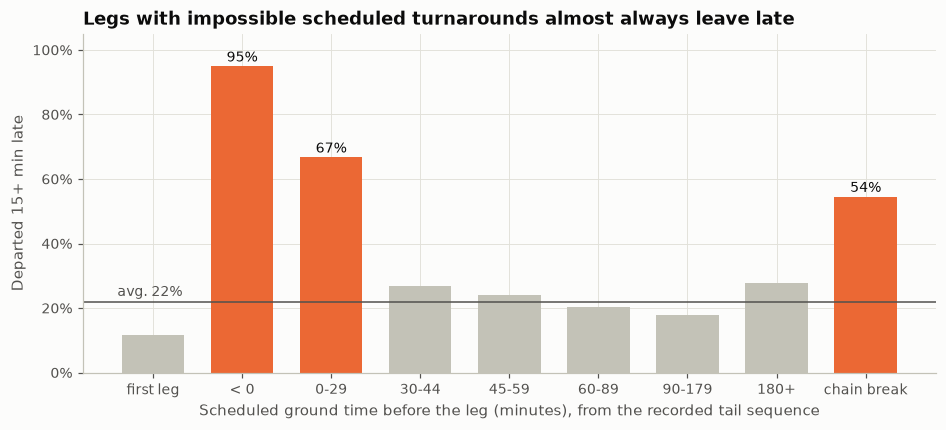

,flights,pct_delayed
bucket,,
first leg,1720530,11.6
< 0,71432,94.9
0-29,65645,66.7
30-44,1063561,26.9
45-59,1608762,24.1
60-89,1610758,20.3
90-179,457048,17.9
180+,220907,27.7
chain break,84385,54.5


In [17]:
planned = rotations.build_rotations(df, df.TAIL_NUM.notna(), order_col="sched_dep")

turn_raw = pd.cut(planned.sched_turn_min, [-np.inf, 0, 30, 45, 60, 90, 180, np.inf], right=False,
                  labels=["< 0", "0-29", "30-44", "45-59", "60-89", "90-179", "180+"])
turn_raw = turn_raw.cat.add_categories(["first leg", "chain break"])
turn_raw[planned.leg_num == 1] = "first leg"
turn_raw[planned.chain_break] = "chain break"
turn_raw = turn_raw.cat.reorder_categories(
    ["first leg", "< 0", "0-29", "30-44", "45-59", "60-89", "90-179", "180+", "chain break"])

turn_table = (df.loc[planned.index, ["DEP_DEL15"]].assign(bucket=turn_raw)
              .dropna(subset=["DEP_DEL15"])
              .groupby("bucket", observed=True).DEP_DEL15
              .agg(flights="size", pct_delayed="mean"))
turn_table["pct_delayed"] = (turn_table.pct_delayed * 100).round(1)
overall_rate = df.DEP_DEL15.mean() * 100

irregular_buckets = ["< 0", "0-29", "chain break"]
fig, ax = plt.subplots(figsize=(10, 4))
colors = [viz.ACCENT if b in irregular_buckets else viz.GRAY for b in turn_table.index]
ax.bar(turn_table.index.astype(str), turn_table.pct_delayed, color=colors, width=0.7)
ax.axhline(overall_rate, color=viz.INK_2, linewidth=1)
ax.text(-0.4, overall_rate + 2, f"avg. {overall_rate:.0f}%", ha="left", color=viz.INK_2, fontsize=9)
for i, (b, row) in enumerate(turn_table.iterrows()):
    if b in irregular_buckets:
        ax.text(i, row.pct_delayed + 1.5, f"{row.pct_delayed:.0f}%", ha="center", fontsize=9)
ax.set(title="Legs with impossible scheduled turnarounds almost always leave late",
       xlabel="Scheduled ground time before the leg (minutes), from the recorded tail sequence",
       ylabel="Departed 15+ min late")
viz.percent(ax.yaxis)
ax.set_ylim(0, 105)
viz.save(fig, "turnaround_leakage", FIG_DIR)
plt.show()
turn_table

**What we see.**
* **Normal turnarounds (30 minutes and up)** carry delay rates close to the 22% average.
* **Impossible turnarounds:**
  * Legs scheduled to leave before the aircraft's previous flight was scheduled to land departed late **95%** of the time (71,432 flights).
  * Turnarounds of 0 to 29 minutes departed late 67% of the time.
  * Legs after a chain break departed late 54% of the time.

**Why this happens.** We think these sequences were never in the airline's original schedule. They show up after the fact, when a delayed or broken aircraft is swapped out and BTS records the replacement tail. A model fed these turnarounds would be partly reading the outcome. Section 1.9 explains how we guard against it.

## 1.9 Feature creation

Features for the delay model (Q2) must be **knowable about two hours before scheduled departure**. Everything below is built from the published schedule, the calendar, or the outcome of an *earlier* flight that had already finished by that cutoff (see `src/features.py`).

| Feature | Meaning | Why it might matter |
|---|---|---|
| `dep_hour`, `arr_hour` | scheduled local hour | delays build up through the day |
| `DAY_OF_WEEK` | 1 = Monday | weekly demand cycle |
| `holiday_window` | within 3 days of a major holiday | holiday travel peaks |
| `origin_hour_deps`, `dest_hour_arrs` | flights scheduled at the same airport in the same hour | congestion |
| `route`, `carrier_origin` | origin-destination pair; carrier at airport | route- and hub-specific performance |
| `log_distance` | log of route miles | long and short flights behave differently |
| `leg_bucket` | aircraft's 1st, 2nd, ... 6th+ flight of the day | more chances to inherit delay |
| `turn_bucket` | scheduled ground time before this leg | less slack, more propagation |
| `prev_landed_by_cutoff`, `prev_delay_at_cutoff` | previous leg's arrival delay, **only if it had landed 2 h before this departure** (otherwise 0) | delay carried in by the aircraft |

**Leakage guard.** The previous cell shows that legs with an impossible scheduled turnaround (< 30 min) or a chain break departed late 55-95% of the time. These sequences exist because airlines **swap aircraft during the day** in response to delays, and BTS records the tail that actually flew. That is day-of information, not schedule. We therefore mark these legs `irregular_sequence`. Their turnaround is replaced with the most common bucket and they get no flag the model could detect. Section 3 also leaves them out of training, so rotation effects are learned only from normal sequences. Validation and test months keep every flight.

In [18]:
df = features.add_calendar_features(df)
df = features.add_congestion_features(df)
df = features.add_route_keys(df)
df = features.add_rotation_features(df, planned)
df["log_distance"] = np.log(df.DISTANCE)
df["log_origin_hour_deps"] = np.log1p(df.origin_hour_deps)
df["log_dest_hour_arrs"] = np.log1p(df.dest_hour_arrs)

new_features = ["dep_hour", "arr_hour", "holiday_window", "origin_hour_deps", "dest_hour_arrs",
                "route", "carrier_origin", "leg_bucket", "turn_bucket",
                "prev_landed_by_cutoff", "prev_delay_at_cutoff"]
print(f"Irregular sequences (kept out of model training): {df.irregular_sequence.sum():,} flights "
      f"({df.irregular_sequence.mean():.1%})")
print(f"Previous leg had landed 2+ hours before departure: {df.prev_landed_by_cutoff.mean():.1%} of flights")
print("Distinct routes:", df.route.nunique(), "| distinct carrier-airport pairs:", df.carrier_origin.nunique())
df[new_features].head()

Irregular sequences (kept out of model training): 253,238 flights (3.6%)
Previous leg had landed 2+ hours before departure: 5.6% of flights
Distinct routes: 6938 | distinct carrier-airport pairs: 1640


,dep_hour,arr_hour,holiday_window,origin_hour_deps,dest_hour_arrs,route,carrier_origin,leg_bucket,turn_bucket,prev_landed_by_cutoff,prev_delay_at_cutoff
0,10,19,1,30,15,302175,302,2,45-59,0,0.0
1,6,9,1,18,35,175302,175,1,first leg,0,0.0
2,8,12,1,8,32,291070,291,1,first leg,0,0.0
3,21,0,1,7,11,175187,175,3,45-59,0,0.0
4,8,11,1,30,25,44187,44,1,first leg,0,0.0


## 1.10 Save the cleaned table

The cleaned table, with every flag and feature, goes to `processed/flights_2025_clean.parquet` on the shared drive. Parquet keeps the column types (categories, dates, nullable integers), so later notebooks can load it in seconds instead of re-cleaning the raw CSVs.

In [19]:
del raw, by_schedule            # free memory; everything needed is in df

clean_path = PROCESSED_DIR / "flights_2025_clean.parquet"
df.to_parquet(clean_path, index=False)

print(f"Saved {len(df):,} rows x {df.shape[1]} columns -> {clean_path.name} "
      f"({clean_path.stat().st_size / 1e6:,.0f} MB)")

Saved 7,001,619 rows x 63 columns -> flights_2025_clean.parquet (314 MB)


## 1.11 Wrangling summary: challenges and how we resolved them

| Challenge | What we found | Resolution |
|---|---|---|
| Inconsistent raw file names | `JUNE` vs `JUN`, an `.csv.csv` extension | month read from the file name, then verified against the data inside |
| Size | 7.0 million rows | load 30 of 33 columns with compact types: about 575 MB, loads in seconds |
| Text dates, float flags | `FL_DATE` as text with a fake midnight; 0/1 flags stored as floats with blanks | parsed with an explicit format (0 mismatches); integer and nullable-integer flags |
| Missing values | all structural: cancellations, diversions, and the BTS cause-reporting rule | verified for all 12 months; causes filled with 0 only where the true value is 0 |
| Contradictory records | 14 late arrivals with zero cause minutes; 1 completed flight without an arrival time | marked unattributed or left blank; documented |
| Tail numbers | Allegiant omits the `N` prefix (137 aircraft) | standardized; no collisions |
| Local times with no time zones | `HHMM` numbers, `2400`, overnight flights, the date line | clock shift recovered from the schedule itself; date-line correction; 227,724 next-day arrivals placed correctly |
| Impossible schedules | 27 durations implying < 30 or > 650 mph | replaced with the route median |
| Heavy-tailed delays | IQR rule would discard 60% of delayed flights | domain-based flags; nothing deleted; 12-hour cap only in averages and plots |
| Rotation ordering | sorting by schedule misorders swapped aircraft (1.14% chain breaks) | order flown legs by actual departure (0.49%); flag the rest |
| Day-of aircraft swaps | 3.6% of flights have impossible recorded sequences and 55-95% of them leave late | leakage guard: neutralized in features and excluded from model training |

**Output:** `processed/flights_2025_clean.parquet` (7,001,619 rows, 63 columns).

# 2. Exploratory data analysis

We organized the EDA around six questions. Each one connects to at least one of our research questions, and each figure is followed by what we took from it.

| | Exploratory question | Feeds |
|---|---|---|
| **EQ1** | How are departure delays distributed, and how common are severe delays? | all |
| **EQ2** | *When* do delays happen: month, day of week, hour, and specific bad days? | Q2 |
| **EQ3** | *Who and where*: which carriers and airports are most delay-prone, and does airport size explain it? | Q1, Q2 |
| **EQ4** | *Why*: what share of delay minutes is attributed to each cause, and how does the mix vary by month and carrier? | Q1 |
| **EQ5** | Does a delay early in an aircraft's day persist through its later flights? | Q3 |
| **EQ6** | Which variables move with delay, and which of them would leak the answer into a model? | Q2 |

Unless stated otherwise, delay analyses use the 6.9 million flights that departed (cancelled flights have no departure delay).

## 2.1 Descriptive statistics

In [20]:
dep = df[df.CANCELLED == 0]     # flights that departed

desc_cols = ["DEP_DELAY", "ARR_DELAY", "CRS_ELAPSED_TIME", "DISTANCE", "origin_hour_deps",
             "n_legs", "sched_turn_min", "prev_arr_delay"]
desc = dep[desc_cols].astype("float64").describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).T
desc["skew"] = dep[desc_cols].astype("float64").skew()
desc.round(1)

,count,mean,std,min,5%,25%,50%,75%,95%,99%,max,skew
DEP_DELAY,6898743.0,13.5,57.4,-115.0,-11.0,-6.0,-2.0,10.0,89.0,225.0,4352.0,10.5
ARR_DELAY,6879484.0,8.5,59.7,-128.0,-28.0,-15.0,-6.0,11.0,91.0,225.0,4336.0,9.5
CRS_ELAPSED_TIME,6898743.0,149.1,73.1,20.0,67.0,95.0,133.0,180.0,308.0,377.0,739.0,1.4
DISTANCE,6898743.0,846.4,603.0,31.0,179.0,404.0,695.0,1084.0,2182.0,2614.0,5095.0,1.4
origin_hour_deps,6898743.0,24.0,21.0,1.0,1.0,7.0,19.0,34.0,68.0,87.0,106.0,1.1
n_legs,6898743.0,4.7,1.6,1.0,2.0,4.0,5.0,6.0,8.0,8.0,14.0,0.2
sched_turn_min,5141702.0,73.0,88.2,-1444.0,30.0,45.0,55.0,70.0,165.0,577.0,1730.0,4.6
prev_arr_delay,5156156.0,4.2,42.9,-128.0,-27.0,-16.0,-7.0,8.0,74.0,185.0,1922.0,5.6


In [21]:
monthly = df.groupby("MONTH").agg(
    flights=("CANCELLED", "size"),
    pct_cancelled=("CANCELLED", "mean"),
    pct_dep_delayed=("DEP_DEL15", "mean"),
    pct_arr_delayed=("ARR_DEL15", "mean"),
    mean_dep_delay=("DEP_DELAY", "mean"),
).astype("float64")
monthly["median_delay_when_late"] = dep[dep.DEP_DEL15 == 1].groupby("MONTH").DEP_DELAY.median()
for col in ["pct_cancelled", "pct_dep_delayed", "pct_arr_delayed"]:
    monthly[col] = (monthly[col] * 100).astype(float).round(1)
monthly["flights"] = monthly.flights.astype(int)
monthly.index = MONTH_NAMES
monthly.round(1)

,flights,pct_cancelled,pct_dep_delayed,pct_arr_delayed,mean_dep_delay,median_delay_when_late
Jan,539747,3.0,18.3,18.8,10.3,41.0
Feb,504884,1.5,19.7,20.8,11.7,43.0
Mar,600872,1.2,19.2,19.6,11.2,43.0
Apr,583950,0.8,18.7,19.7,10.4,42.0
May,605648,1.0,22.5,23.6,14.2,44.0
Jun,611575,1.6,27.5,28.3,19.3,46.0
Jul,631428,2.5,28.6,28.9,21.5,48.0
Aug,602378,1.1,22.4,22.6,14.3,43.0
Sep,562439,0.5,16.5,16.6,8.1,40.0
Oct,605844,0.5,19.6,20.3,10.3,39.0


In [22]:
print(f"Carriers: {df.OP_UNIQUE_CARRIER.nunique()} | airports: {df.ORIGIN.nunique()} | "
      f"routes: {df.route.nunique():,} | aircraft (tails): {df.TAIL_NUM.nunique():,} | "
      f"aircraft-days flown: {int((dep.leg_num == 1).sum()):,}")
print(f"Share of departures 15+ min late: {dep.DEP_DEL15.mean():.1%} | "
      f"share of arrivals 15+ min late: {dep.ARR_DEL15.mean():.1%} | "
      f"cancelled: {df.CANCELLED.mean():.2%}")
cancel_codes = (df.CANCELLATION_CODE.value_counts()
                .rename({"A": "A carrier", "B": "B weather", "C": "C NAS", "D": "D security"}))
print("Cancellation reasons:", (cancel_codes / cancel_codes.sum() * 100).round(1).to_dict())

Carriers: 14 | airports: 352 | routes: 6,938 | aircraft (tails): 6,133 | aircraft-days flown: 1,731,697
Share of departures 15+ min late: 21.7% | share of arrivals 15+ min late: 22.3% | cancelled: 1.47%
Cancellation reasons: {'B weather': 61.6, 'A carrier': 20.3, 'C NAS': 18.0, 'D security': 0.0}


**What we see.**
* **Delays are extremely skewed.** Departure delay has a median of **-2 minutes** (the typical flight leaves early), but a mean of +13.5 and a skewness of 10.5. A few very long delays pull the average up, so throughout the EDA we report medians and rates alongside means.
* **Overall rates:** 21.7% of departures and 22.3% of arrivals were 15+ minutes late. 1.47% of flights were cancelled, and **62% of cancellations were attributed to weather**.
* **Seasonality:**
  * Delay rates peak in **July (28.6%)**, June (27.5%) and **December (26.9%)**, and bottom out in **September (16.5%)**.
  * Cancellations peak in **January (3.0%)**, the winter-storm month, followed by July and November (2.5% each).
* **Severity is fairly stable:** once a flight is late, the median delay stays between 39 and 48 minutes in every month.
* **Network size:** the schedule spans 14 carriers, 352 airports, 6,938 routes and 6,133 aircraft.

## 2.2 EQ1: How are departure delays distributed?

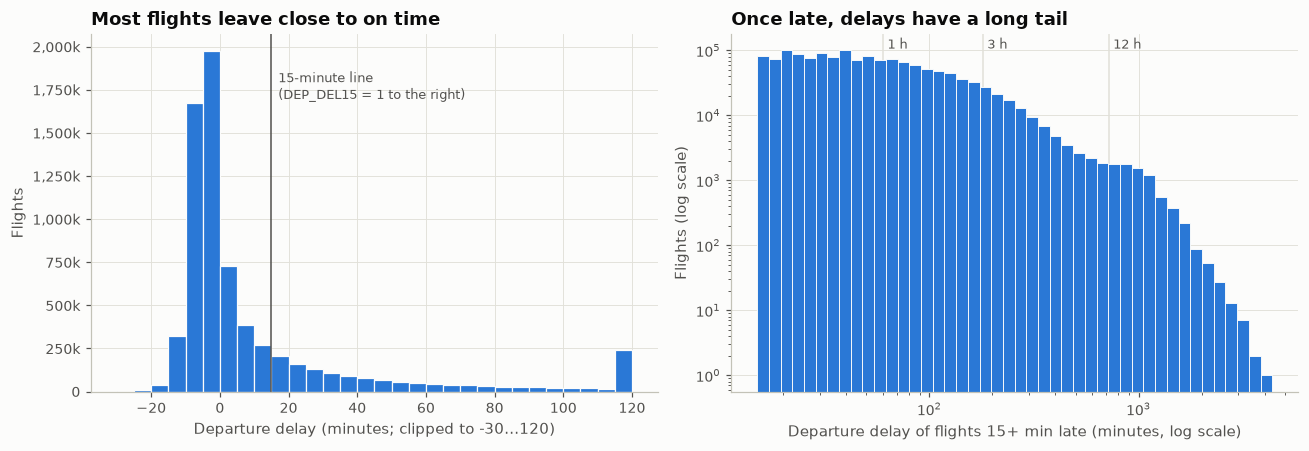

Median -2 min | mean 13.5 min | skewness 10.5 | 58% left early | 8.0% left 1 h+ late | 1.61% left 3 h+ late


In [23]:
delay = dep.DEP_DELAY.astype("float64")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

ax = axes[0]
ax.hist(delay.clip(-30, 120), bins=np.arange(-30, 125, 5), color=viz.BLUE, edgecolor=viz.SURFACE, linewidth=0.8)
ax.axvline(15, color=viz.INK_2, linewidth=1)
ax.text(17, ax.get_ylim()[1] * 0.9, "15-minute line\n(DEP_DEL15 = 1 to the right)", fontsize=8.5, color=viz.INK_2, va="top")
ax.set(title="Most flights leave close to on time",
       xlabel="Departure delay (minutes; clipped to -30...120)", ylabel="Flights")
viz.thousands(ax.yaxis)

ax = axes[1]
late = delay[delay >= 15]
bins = np.logspace(np.log10(15), np.log10(late.max() + 1), 45)
ax.hist(late, bins=bins, color=viz.BLUE, edgecolor=viz.SURFACE, linewidth=0.6)
ax.set_xscale("log")
ax.set_yscale("log")
for minutes, label in [(60, "1 h"), (180, "3 h"), (720, "12 h")]:
    ax.axvline(minutes, color=viz.GRID, linewidth=1, zorder=0)
    ax.text(minutes * 1.05, ax.get_ylim()[1] * 0.6, label, fontsize=8.5, color=viz.INK_2)
ax.set(title="Once late, delays have a long tail",
       xlabel="Departure delay of flights 15+ min late (minutes, log scale)", ylabel="Flights (log scale)")
fig.tight_layout()
viz.save(fig, "eq1_delay_distribution", FIG_DIR)
plt.show()

print(f"Median {delay.median():.0f} min | mean {delay.mean():.1f} min | skewness {delay.skew():.1f} | "
      f"{(delay < 0).mean():.0%} left early | {(delay >= 60).mean():.1%} left 1 h+ late | "
      f"{(delay >= 180).mean():.2%} left 3 h+ late")

**Interpretation.**
* **The bulk:** most flights cluster just before their scheduled time. 58% push back early, and the mode is 5 to 10 minutes early.
* **The tail:** past the 15-minute line, counts fall steadily rather than dropping off. On log-log axes the decline is close to a straight line from 15 minutes out to about 12 hours, which is what you would expect from a heavy-tailed distribution. 8.0% of departures are an hour or more late and 1.6% three hours or more, with a small bump around 12 to 24 hours from flights pushed to the next day.
* **Implications for the project:**
  * Averages of raw minutes would be dominated by a few extreme flights, so later analyses cap at 12 hours or use rates and medians.
  * A 15-minute yes/no target is a sensible prediction goal, since it does not depend on how extreme a delay gets.

## 2.3 EQ2: When do delays happen?

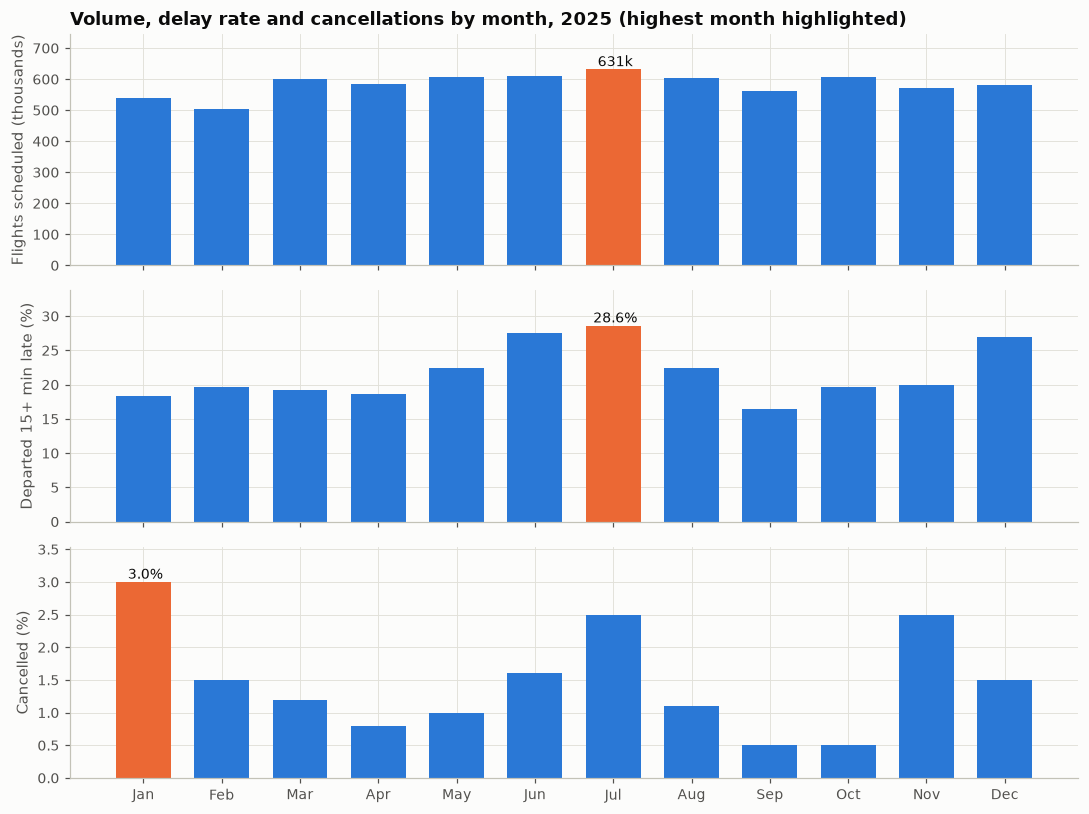

In [24]:
fig, axes = plt.subplots(3, 1, figsize=(10, 7.5), sharex=True)
panels = [
    ("flights", "Flights scheduled (thousands)", 1 / 1000, "{:.0f}k"),
    ("pct_dep_delayed", "Departed 15+ min late (%)", 1, "{:.1f}%"),
    ("pct_cancelled", "Cancelled (%)", 1, "{:.1f}%"),
]
for ax, (col, label, scale, fmt) in zip(axes, panels):
    values = monthly[col] * scale
    top = values.idxmax()
    colors = [viz.ACCENT if m == top else viz.BLUE for m in values.index]
    ax.bar(values.index, values, color=colors, width=0.7)
    ax.text(list(values.index).index(top), values[top], " " + fmt.format(values[top]),
            ha="center", va="bottom", fontsize=9)
    ax.set_ylabel(label)
    ax.set_ylim(0, values.max() * 1.18)
axes[0].set_title("Volume, delay rate and cancellations by month, 2025 (highest month highlighted)")
fig.tight_layout()
viz.save(fig, "eq2_monthly", FIG_DIR)
plt.show()

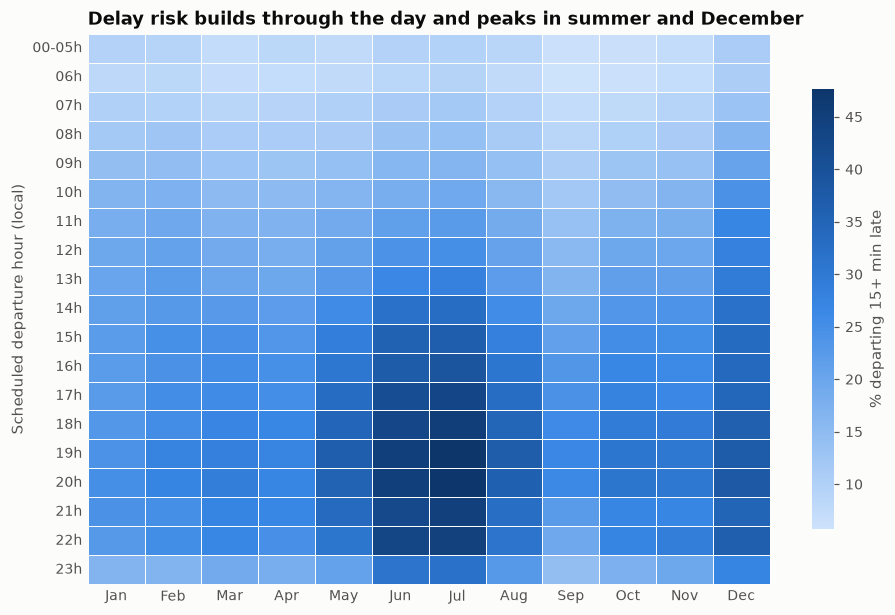

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
00-05h,10,9,7,8,8,10,10,9,6,7,7,11
06h,8,8,7,7,8,9,9,8,6,6,7,11
07h,10,10,9,9,10,11,12,9,7,8,9,13
08h,12,13,11,11,11,13,14,11,9,10,11,16
09h,14,15,13,13,14,16,16,14,11,13,14,21
10h,17,17,15,15,16,18,19,16,12,15,17,24
11h,18,19,17,17,19,22,22,19,14,17,18,27
12h,20,21,19,18,21,24,25,21,16,20,20,28
13h,20,22,20,20,23,27,28,22,17,21,21,29
14h,22,23,23,22,26,32,33,26,20,23,24,32


In [25]:
heat = dep.pivot_table(index="DEP_TIME_BLK", columns="MONTH", values="DEP_DEL15",
                       aggfunc="mean", observed=True).astype(float) * 100
heat.columns = MONTH_NAMES
heat.index = [("00-05" if b.startswith("0001") else b[:2]) + "h" for b in heat.index.astype(str)]

fig, ax = plt.subplots(figsize=(10, 6.5))
sns.heatmap(heat, cmap=viz.SEQUENTIAL, linewidths=0.6, linecolor=viz.SURFACE,
            cbar_kws={"label": "% departing 15+ min late", "shrink": 0.8}, ax=ax)
ax.set(title="Delay risk builds through the day and peaks in summer and December",
       xlabel="", ylabel="Scheduled departure hour (local)")
ax.tick_params(length=0)
viz.save(fig, "eq2_hour_month_heatmap", FIG_DIR)
plt.show()
heat.round(0).astype(int)

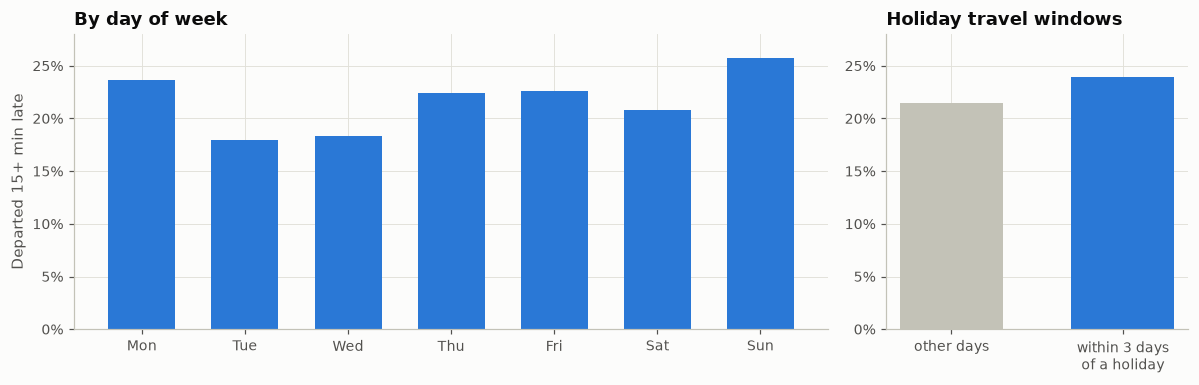

{'Mon': 23.6, 'Tue': 17.9, 'Wed': 18.3, 'Thu': 22.4, 'Fri': 22.6, 'Sat': 20.8, 'Sun': 25.7} | {'other days': 21.5, 'within 3 days\nof a holiday': 23.9}


In [26]:
by_dow = dep.groupby("DAY_OF_WEEK").DEP_DEL15.mean().astype(float) * 100
by_dow.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
by_holiday = dep.groupby("holiday_window").DEP_DEL15.mean().astype(float) * 100
by_holiday.index = ["other days", "within 3 days\nof a holiday"]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [3, 1.2]})
axes[0].bar(by_dow.index, by_dow, color=viz.BLUE, width=0.65)
axes[0].set(title="By day of week", ylabel="Departed 15+ min late")
axes[1].bar(by_holiday.index, by_holiday, color=[viz.GRAY, viz.BLUE], width=0.6)
axes[1].set(title="Holiday travel windows")
for ax in axes:
    viz.percent(ax.yaxis)
    ax.set_ylim(0, 28)
fig.tight_layout()
viz.save(fig, "eq2_weekday_holiday", FIG_DIR)
plt.show()
print(by_dow.round(1).to_dict(), "|", by_holiday.round(1).to_dict())

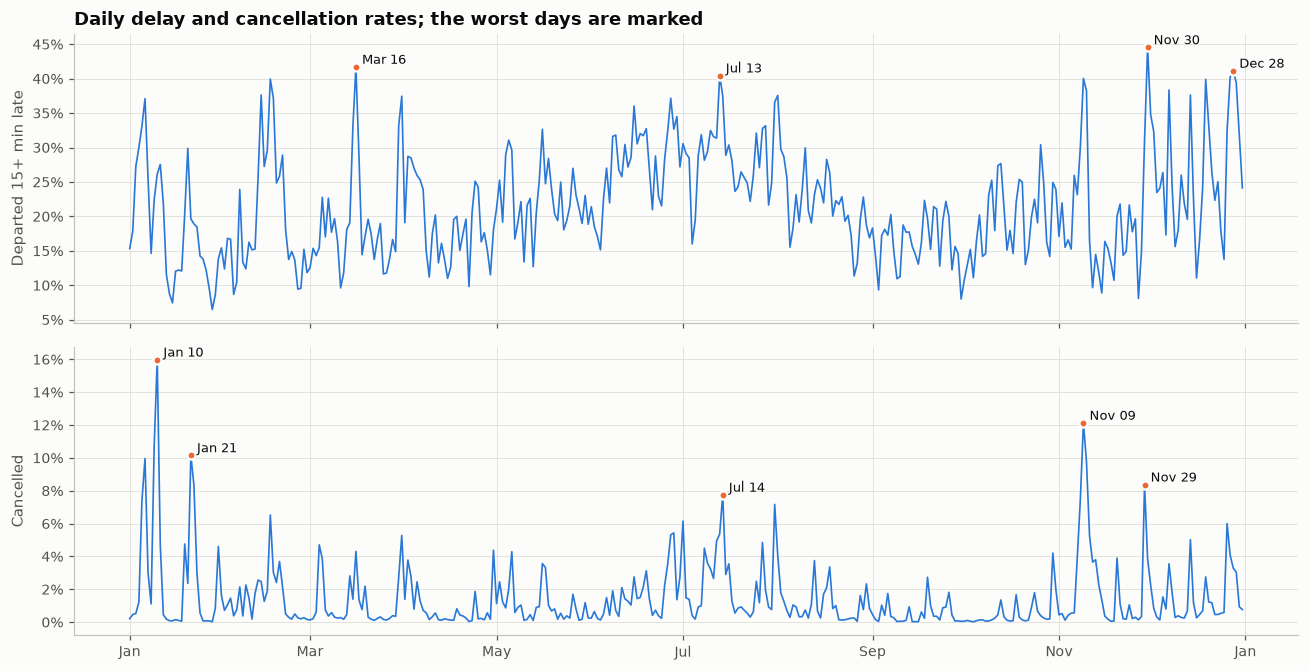

,flights,pct_cancelled,pct_delayed
FL_DATE,,,
Fri Jan 10,17873,16.0,26.1
Sun Nov 09,20442,12.1,40.0
Thu Jan 09,17952,10.7,22.4
Tue Jan 21,16034,10.2,19.6
Mon Jan 06,18732,10.0,37.1
Mon Nov 10,20224,9.8,38.3
Sat Nov 29,20216,8.4,31.1
Wed Jan 22,16244,8.3,18.9


In [27]:
daily = df.groupby("FL_DATE").agg(flights=("CANCELLED", "size"),
                                  pct_cancelled=("CANCELLED", "mean"),
                                  pct_delayed=("DEP_DEL15", "mean"))
daily[["pct_cancelled", "pct_delayed"]] = daily[["pct_cancelled", "pct_delayed"]].astype(float) * 100

fig, axes = plt.subplots(2, 1, figsize=(12, 6.2), sharex=True)
for ax, col, label, n_label in [(axes[0], "pct_delayed", "Departed 15+ min late", 4),
                                (axes[1], "pct_cancelled", "Cancelled", 5)]:
    ax.plot(daily.index, daily[col], color=viz.BLUE, linewidth=1.1)
    ax.set_ylabel(label)
    viz.percent(ax.yaxis)
    labelled = []
    for day, value in daily[col].sort_values(ascending=False).items():
        if len(labelled) == n_label:
            break
        if any(abs((day - other).days) < 10 for other in labelled):
            continue                                   # one label per event
        labelled.append(day)
        ax.scatter(day, value, s=28, color=viz.ACCENT, zorder=3, edgecolor=viz.SURFACE, linewidth=1.5)
        ax.annotate(day.strftime("%b %d"), (day, value), xytext=(4, 2), textcoords="offset points", fontsize=8.5)
axes[0].set_title("Daily delay and cancellation rates; the worst days are marked")
axes[1].xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%b"))
fig.tight_layout()
viz.save(fig, "eq2_daily", FIG_DIR)
plt.show()

worst = daily.sort_values("pct_cancelled", ascending=False).head(8).round(1)
worst.index = worst.index.strftime("%a %b %d")
worst

**Interpretation.**
* **Within the day:** delay risk rises steadily from morning to evening in every month, roughly 6-11% for 6 a.m. departures to 24-48% for 7-8 p.m. departures, then eases for the last late-night flights. Planes start the morning mostly on time and pick up delay as the day goes on. This is the same propagation Q3 will measure directly, and it is why departure hour is the strongest single predictor in Section 3.
* **Across the year:** summer is the worst season. June and July evenings exceed 40% delayed, consistent with afternoon thunderstorms over the busiest hubs. December is different: even its *morning* departures are delayed more than other months' (16% at 8 a.m. versus 9-14% in the other months), pointing to day-long disruption (winter weather plus holiday loads) rather than just evening build-up. September is the calmest month.
* **Day of week:** Sunday (25.7%) and Monday (23.6%) are worst and Tuesday and Wednesday best (about 18%). Days within three days of a major holiday run 2.4 points above other days.
* **Anomalies:**
  * The worst cancellation days cluster into a few events: **January 6-10** (16% cancelled on Jan 10), **January 21-22**, and **November 8-10** (12% on Nov 9, with 40% of the remaining flights delayed).
  * The worst delay days are **Nov 30** (45%), Mar 16, Jul 13 and Dec 28. Nov 30 is the Sunday after Thanksgiving, one of the heaviest travel days of the year.
  * These dates line up with widely reported events: early-January winter storms, the rare Gulf Coast snowstorm of January 21, and FAA-ordered flight reductions at major airports during the November 2025 government shutdown. We will confirm each with the weather data rather than assume.
  * For modeling, these spikes are why the test months (Nov-Dec) are harder than an average month.

## 2.4 EQ3: Which carriers and airports are most delay-prone?

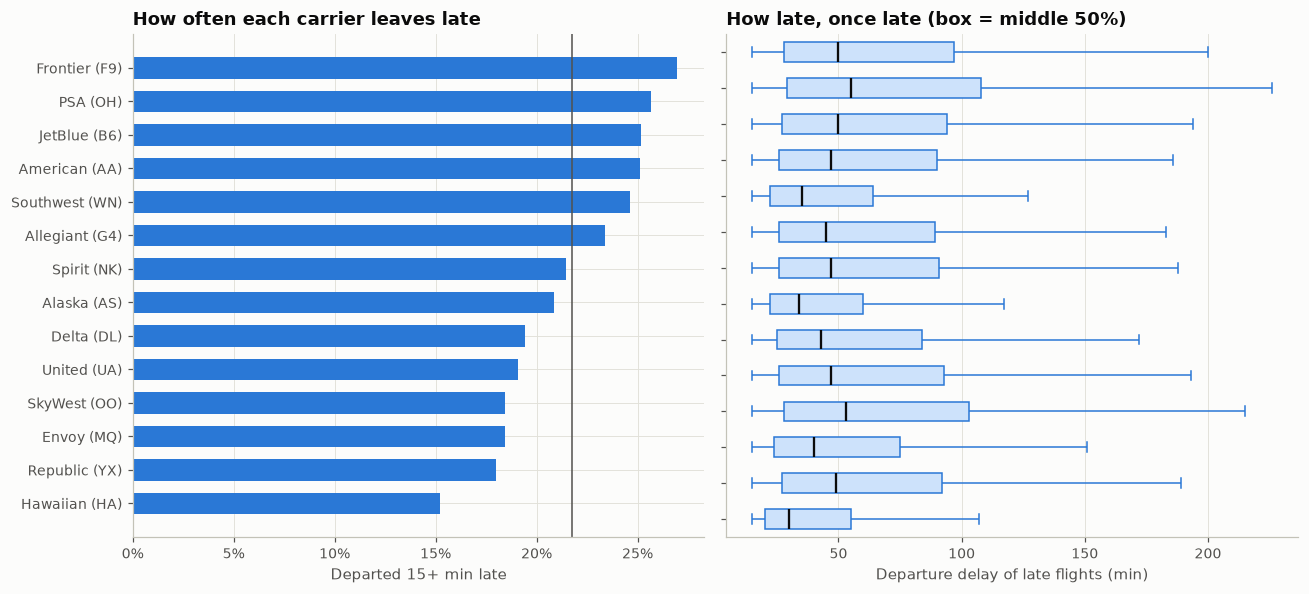

,flights,pct_delayed,median_delay_when_late,pct_cancelled
OP_UNIQUE_CARRIER,,,,
F9,194557,27.0,50.0,1.8
OH,237341,25.6,55.0,4.6
B6,227588,25.2,50.0,1.7
AA,955974,25.1,47.0,1.8
WN,1380086,24.6,35.0,0.8
G4,130284,23.4,45.0,0.5
NK,191588,21.4,47.0,1.5
AS,242614,20.9,34.0,1.2
DL,1015218,19.4,43.0,1.1


In [28]:
carrier_stats = dep.groupby("OP_UNIQUE_CARRIER", observed=True).agg(
    flights=("DEP_DEL15", "size"), pct_delayed=("DEP_DEL15", "mean"))
carrier_stats["pct_delayed"] = carrier_stats.pct_delayed.astype(float) * 100
carrier_stats["median_delay_when_late"] = (dep[dep.DEP_DEL15 == 1]
                                           .groupby("OP_UNIQUE_CARRIER", observed=True).DEP_DELAY.median())
carrier_stats["pct_cancelled"] = df.groupby("OP_UNIQUE_CARRIER", observed=True).CANCELLED.mean() * 100
carrier_stats = carrier_stats.sort_values("pct_delayed", ascending=False)
labels = [f"{CARRIER_NAMES[c]} ({c})" for c in carrier_stats.index]

late_flights = dep.loc[dep.DEP_DEL15 == 1, ["OP_UNIQUE_CARRIER", "DEP_DELAY"]].copy()
late_flights["carrier"] = late_flights.OP_UNIQUE_CARRIER.map(lambda c: f"{CARRIER_NAMES[c]} ({c})").astype(str)

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
positions = np.arange(len(labels))
axes[0].barh(positions, carrier_stats.pct_delayed, color=viz.BLUE, height=0.65)
axes[0].set_yticks(positions, labels)
axes[0].invert_yaxis()                      # worst carrier on top
axes[0].axvline(dep.DEP_DEL15.mean() * 100, color=viz.INK_2, linewidth=1)
axes[0].set(title="How often each carrier leaves late", xlabel="Departed 15+ min late")
viz.percent(axes[0].xaxis)
sns.boxplot(data=late_flights, y="carrier", x="DEP_DELAY", order=labels, orient="h", showfliers=False,
            width=0.55, linewidth=1, ax=axes[1],
            boxprops={"facecolor": "#cde2fb", "edgecolor": viz.BLUE},
            medianprops={"color": viz.INK, "linewidth": 1.5},
            whiskerprops={"color": viz.BLUE}, capprops={"color": viz.BLUE})
axes[1].set(title="How late, once late (box = middle 50%)", xlabel="Departure delay of late flights (min)", ylabel="")
axes[1].set_yticklabels([])                 # same carrier order as the left panel
fig.tight_layout()
viz.save(fig, "eq3_carriers", FIG_DIR)
plt.show()
carrier_stats.round(1)

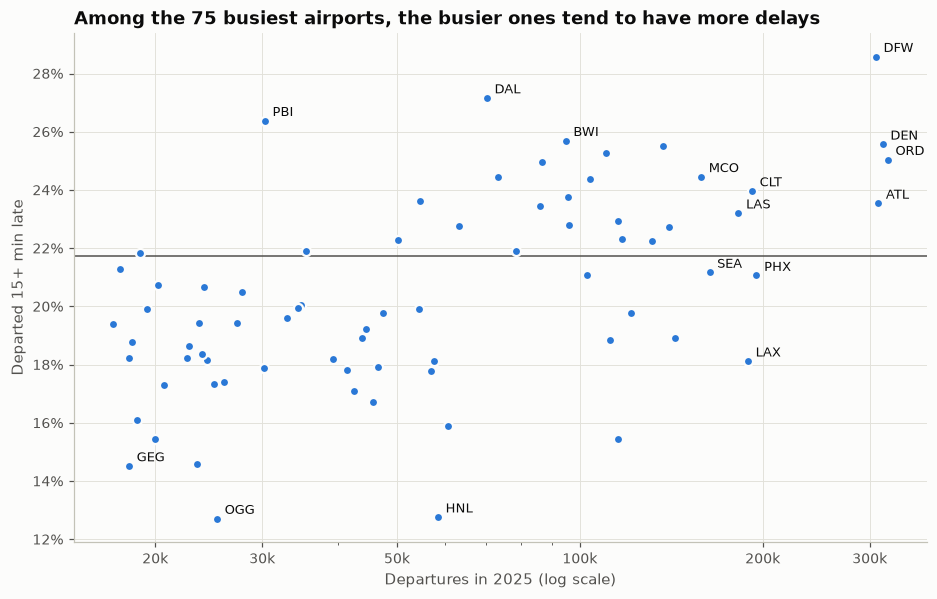

Spearman correlation, departures vs % delayed: 0.54 (75 busiest), 0.13 (all 235 airports with 1,000+ departures)


,departures,pct_delayed
ORIGIN,,
DFW,307148,28.6
DAL,70315,27.2
PBI,30308,26.4
BWI,94808,25.7
DEN,315242,25.6
OGG,25284,12.7
HNL,58414,12.8
GEG,18114,14.5
BOI,23418,14.6


In [29]:
airport_stats = dep.groupby("ORIGIN", observed=True).agg(
    departures=("DEP_DEL15", "size"), pct_delayed=("DEP_DEL15", "mean"))
airport_stats["pct_delayed"] = airport_stats.pct_delayed.astype(float) * 100
big = airport_stats.nlargest(75, "departures")

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(big.departures, big.pct_delayed, s=36, color=viz.BLUE, edgecolor=viz.SURFACE, linewidth=1.5, zorder=3)
ax.set_xscale("log")
to_label = set(big.nlargest(10, "departures").index) | set(big.nlargest(4, "pct_delayed").index) \
           | set(big.nsmallest(3, "pct_delayed").index)
for code_, row in big.loc[list(to_label)].iterrows():
    ax.annotate(code_, (row.departures, row.pct_delayed), xytext=(5, 3), textcoords="offset points", fontsize=8.5)
ax.axhline(dep.DEP_DEL15.mean() * 100, color=viz.INK_2, linewidth=1)
ax.set(title="Among the 75 busiest airports, the busier ones tend to have more delays",
       xlabel="Departures in 2025 (log scale)", ylabel="Departed 15+ min late")
ax.set_xticks([20_000, 30_000, 50_000, 100_000, 200_000, 300_000])
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.FuncFormatter(lambda v, _: f"{v / 1000:,.0f}k"))
ax.xaxis.set_minor_formatter(plt.matplotlib.ticker.NullFormatter())
viz.percent(ax.yaxis)
viz.save(fig, "eq3_airports", FIG_DIR)
plt.show()

rho_big = big[["departures", "pct_delayed"]].corr(method="spearman").iloc[0, 1]
mid = airport_stats[airport_stats.departures >= 1000]
rho_all = mid[["departures", "pct_delayed"]].corr(method="spearman").iloc[0, 1]
print(f"Spearman correlation, departures vs % delayed: {rho_big:.2f} (75 busiest), "
      f"{rho_all:.2f} (all {len(mid)} airports with 1,000+ departures)")
pd.concat([big.nlargest(5, "pct_delayed"), big.nsmallest(5, "pct_delayed")])[["departures", "pct_delayed"]].round(1)

**Interpretation.**
* **Carriers differ in both how often and how badly they run late.**
  * **Frontier (27.0%)**, PSA, JetBlue, American and Southwest leave late most often. **Hawaiian (15.2%)** and the regional carriers Republic, Envoy and SkyWest least often.
  * Frequency and severity are different things. Southwest is late often (24.6%), but its median late flight is only 35 minutes late; only Hawaiian (30) and Alaska (34) are shorter. PSA and SkyWest flights, once late, are the latest (medians of 55 and 53 minutes).
  * Regional carriers cancel the most: **PSA 4.6%, Republic 3.3%, Envoy 2.2%**, against roughly 1% for most mainline carriers. Republic and Envoy have low delay rates but high cancellation rates. Our guess is that mainline airlines cancel regional flights first when things go wrong, so delay rates alone make these carriers look better than they are. We need to keep cancellations in mind for Q1.
* **Airports: size matters among hubs, not overall.**
  * Among the 75 busiest airports, busier ones tend to be later (Spearman 0.54). Dallas/Fort Worth (28.6%), Dallas Love (27.2%), Denver and Chicago O'Hare are among the worst.
  * Across all 235 airports with 1,000+ departures, the relationship nearly vanishes (0.13).
  * Location and carrier mix matter at least as much as size. Both Dallas airports rank high, which suggests a regional factor (Texas convective weather). Southwest bases such as Dallas Love, Baltimore and Denver track Southwest's own high rate. Hawaiian airports (Kahului 12.7%, Honolulu 12.8%) are the most punctual.
  * This motivates the airport, route and carrier-at-airport rate features in the model.

## 2.5 EQ4: What causes the delay minutes?

Cause minutes exist only for flights that arrived 15+ minutes late. We sum the minutes in each cause and take shares, leaving out the 14 unattributed flights. This is a first pass at **Q1**.

1,534,624 late arrivals, 111.9 million delay minutes


,Carrier,Weather,NAS (air traffic system),Security,Late-arriving aircraft
% of delay minutes,32.4,6.4,21.9,0.1,39.2


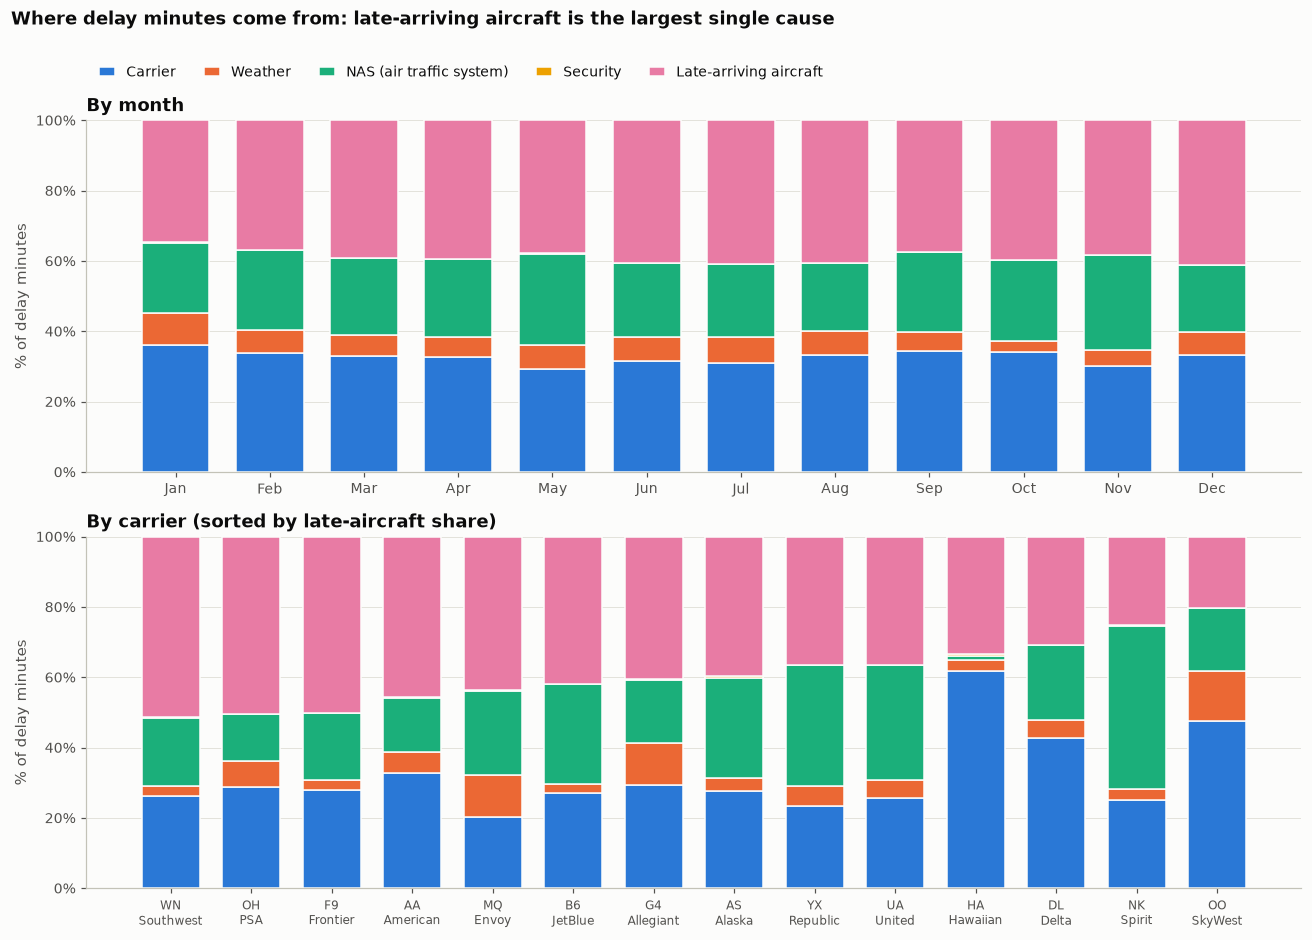

,Carrier,Weather,NAS (air traffic system),Security,Late-arriving aircraft
Jan,36.2,9.1,19.9,0.2,34.7
Feb,33.9,6.6,22.5,0.1,36.9
Mar,33.0,5.9,21.9,0.1,39.2
Apr,32.7,5.5,22.2,0.2,39.4
May,29.3,6.9,25.9,0.1,37.8
Jun,31.6,6.9,20.9,0.2,40.6
Jul,31.1,7.3,20.7,0.1,40.8
Aug,33.1,7.0,19.2,0.1,40.5
Sep,34.3,5.6,22.6,0.1,37.4
Oct,34.0,3.3,22.9,0.1,39.7


In [30]:
attributed = df.ARR_DEL15.eq(1).fillna(False).astype(bool) & ~df.cause_unattributed
late_arrivals = df.loc[attributed, ["MONTH", "OP_UNIQUE_CARRIER"] + clean.CAUSE_COLS]
late_arrivals[clean.CAUSE_COLS] = late_arrivals[clean.CAUSE_COLS].astype("float64")

totals = late_arrivals[clean.CAUSE_COLS].sum()
cause_share = (totals / totals.sum() * 100).rename(index=CAUSE_LABELS)
print(f"{attributed.sum():,} late arrivals, {totals.sum() / 1e6:,.1f} million delay minutes")
display(cause_share.round(1).to_frame("% of delay minutes").T)

def shares(group_col):
    minutes = late_arrivals.groupby(group_col, observed=True)[clean.CAUSE_COLS].sum()
    return minutes.div(minutes.sum(axis=1), axis=0).mul(100).rename(columns=CAUSE_LABELS)

month_share = shares("MONTH")
month_share.index = MONTH_NAMES
carrier_share = shares("OP_UNIQUE_CARRIER").sort_values("Late-arriving aircraft", ascending=False)
carrier_share.index = [f"{c}\n{CARRIER_NAMES[c]}" for c in carrier_share.index]

fig, axes = plt.subplots(2, 1, figsize=(12, 8.5))
for ax, table, title in [
    (axes[0], month_share, "By month"),
    (axes[1], carrier_share, "By carrier (sorted by late-aircraft share)"),
]:
    bottom = np.zeros(len(table))
    for cause, color in viz.CAUSE_COLORS.items():
        ax.bar(table.index, table[cause], bottom=bottom, color=color, width=0.72,
               edgecolor=viz.SURFACE, linewidth=1, label=cause)
        bottom += table[cause].to_numpy()
    ax.set_ylim(0, 100)
    ax.set_title(title)
    ax.set_ylabel("% of delay minutes")
    viz.percent(ax.yaxis)
    ax.grid(axis="x", visible=False)
axes[1].tick_params(axis="x", labelsize=8)
axes[0].legend(ncol=5, loc="lower left", bbox_to_anchor=(0, 1.08), handlelength=1.2)
fig.suptitle("Where delay minutes come from: late-arriving aircraft is the largest single cause",
             x=0.01, ha="left", fontweight="bold", y=1.0)
fig.tight_layout()
viz.save(fig, "eq4_cause_composition", FIG_DIR)
plt.show()
month_share.round(1)

In [31]:
carrier_share.round(1)

,Carrier,Weather,NAS (air traffic system),Security,Late-arriving aircraft
WN\nSouthwest,26.2,3.0,19.3,0.2,51.3
OH\nPSA,28.7,7.4,13.4,0.1,50.4
F9\nFrontier,27.8,2.9,19.0,0.0,50.3
AA\nAmerican,32.7,5.9,15.6,0.1,45.7
MQ\nEnvoy,20.3,11.8,24.0,0.1,43.7
B6\nJetBlue,27.0,2.7,28.3,0.2,41.8
G4\nAllegiant,29.5,11.7,18.0,0.4,40.4
AS\nAlaska,27.7,3.5,28.6,0.5,39.7
YX\nRepublic,23.2,5.7,34.4,0.1,36.6
UA\nUnited,25.6,5.2,32.7,0.0,36.5


**Interpretation (first answer to Q1).**
* **Overall shares:** across 1.53 million late arrivals and **112 million delay minutes**, the shares are:
  * **late-arriving aircraft, 39.2%**
  * carrier, 32.4%
  * NAS (air traffic system), 21.9%
  * weather, only 6.4%
  * security, 0.1%

  The biggest category is the one that doesn't say where the delay started, which is what our project is trying to figure out.
* **By month:**
  * Weather's share is highest in January (9.1%) and lowest in October (3.3%).
  * NAS peaks in **November (26.8%)**, consistent with the air-traffic-control staffing problems behind that month's flight reductions.
  * The late-aircraft share ranges from 35% (January) to 41% (December).
* **By carrier, the mix differs far more than by month:**
  * Southwest, PSA and Frontier attribute about **half** their delay minutes to late-arriving aircraft, consistent with networks that keep aircraft flying many short legs with quick turns.
  * Spirit attributes 46% to NAS.
  * Hawaiian attributes 62% to its own operations (carrier).
  * SkyWest and Envoy report the most weather (14% and 12%).
* **Caveat on weather:** the direct weather share is small, but storms also drive NAS programs (ground stops, flow control) and, through late aircraft, carry into later flights. Measuring that hidden weather share is the stretch goal of Q1 and the reason for the weather data in the final.

## 2.6 EQ5: Does an early delay persist through the aircraft's day?

A first look at **Q3** using the rebuilt rotations. To keep the comparison fair, the right-hand chart uses only aircraft-days with at least five legs and no data problems (no chain break, no tail conflict), so the same aircraft-days appear at every leg. Delays are counted in minutes late (early departures count as 0) and capped at 12 hours.

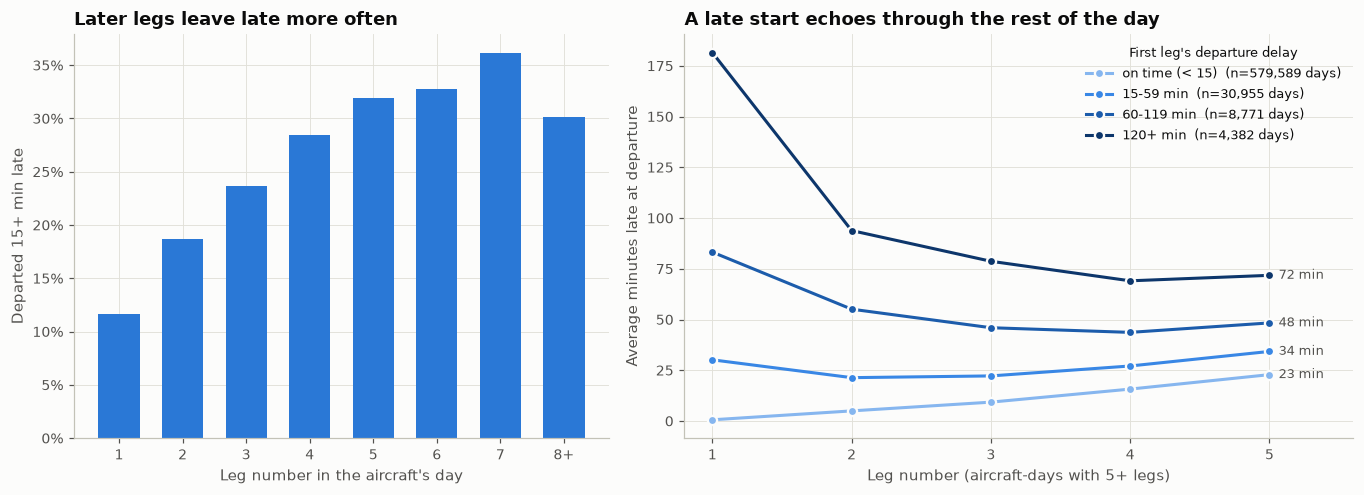

Departed 15+ min late, by leg number (%): {'1': 11.7, '2': 18.7, '3': 23.7, '4': 28.5, '5': 31.9, '6': 32.8, '7': 36.1, '8+': 30.1}
Extra minutes late compared with aircraft that started on time:


first_leg_band,15-59 min,60-119 min,120+ min
leg_num,,,
1,29.6,82.6,180.9
2,16.4,50.1,88.9
3,12.9,36.7,69.4
4,11.4,27.9,53.3
5,11.4,25.5,48.9


first_leg_band,on time (< 15),15-59 min,60-119 min,120+ min
leg_num,,,,
1,0.6,30.2,83.2,181.5
2,5.0,21.4,55.1,93.8
3,9.3,22.2,46.0,78.7
4,15.7,27.1,43.7,69.1
5,22.8,34.3,48.3,71.8


In [32]:
legs = dep[dep.leg_num.notna()].copy()
legs["minutes_late"] = legs.DEP_DELAY_NEW.astype("float64").clip(upper=clean.EXTREME_DELAY_MIN)

by_leg = legs.groupby(legs.leg_num.clip(upper=8)).DEP_DEL15.mean().astype(float) * 100
by_leg.index = [str(int(i)) if i < 8 else "8+" for i in by_leg.index]

bad_day = legs.groupby("aircraft_day")[["chain_break", "tail_conflict"]].transform("max").any(axis=1)
long_days = legs[(legs.n_legs >= 5) & ~bad_day & (legs.leg_num <= 5)].copy()
first_delay = long_days.loc[long_days.leg_num == 1].set_index("aircraft_day").minutes_late
long_days["first_leg_band"] = pd.cut(long_days.aircraft_day.map(first_delay), [-1, 14, 59, 119, np.inf],
                                     labels=["on time (< 15)", "15-59 min", "60-119 min", "120+ min"])
persistence = long_days.pivot_table(index="leg_num", columns="first_leg_band", values="minutes_late",
                                    aggfunc="mean", observed=True)
band_days = long_days[long_days.leg_num == 1].first_leg_band.value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6), gridspec_kw={"width_ratios": [1, 1.25]})
axes[0].bar(by_leg.index, by_leg, color=viz.BLUE, width=0.65)
axes[0].set(title="Later legs leave late more often", xlabel="Leg number in the aircraft's day",
            ylabel="Departed 15+ min late")
viz.percent(axes[0].yaxis)

ax = axes[1]
for band, color in zip(persistence.columns, viz.ORDINAL_4):
    ax.plot(persistence.index, persistence[band], marker="o", markersize=6, color=color,
            markeredgecolor=viz.SURFACE, markeredgewidth=1.5, label=f"{band}  (n={band_days[band]:,} days)")
    ax.annotate(f"{persistence[band].iloc[-1]:.0f} min", (persistence.index[-1], persistence[band].iloc[-1]),
                xytext=(6, 0), textcoords="offset points", va="center", fontsize=8.5, color=viz.INK_2)
ax.set_xticks(range(1, 6))
ax.set_xlim(0.8, 5.6)
ax.set(title="A late start echoes through the rest of the day", xlabel="Leg number (aircraft-days with 5+ legs)",
       ylabel="Average minutes late at departure")
ax.legend(title="First leg's departure delay", loc="upper right", fontsize=8.5, title_fontsize=8.5)
fig.tight_layout()
viz.save(fig, "eq5_propagation", FIG_DIR)
plt.show()
print("Departed 15+ min late, by leg number (%):", by_leg.round(1).to_dict())
excess = persistence.sub(persistence["on time (< 15)"], axis=0).drop(columns="on time (< 15)")
print("Extra minutes late compared with aircraft that started on time:")
display(excess.round(1))
persistence.round(1)

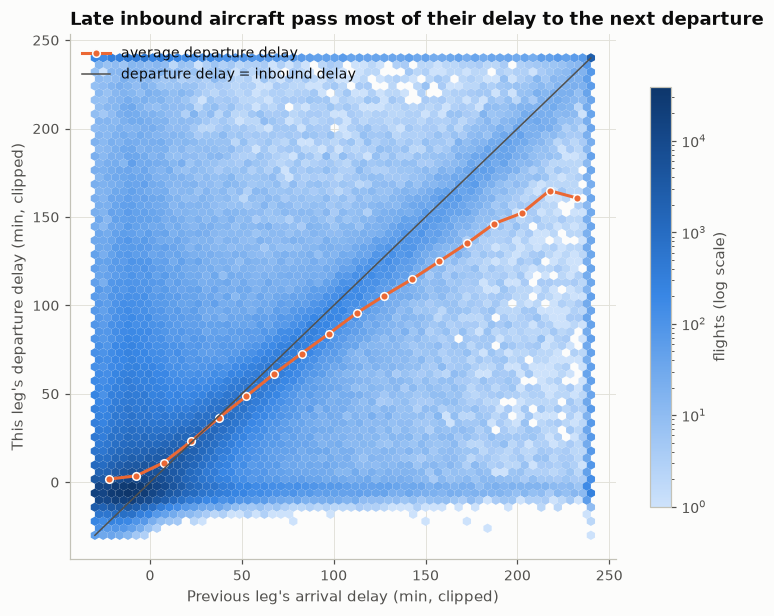

Correlation between inbound arrival delay and departure delay: Pearson 0.62, Spearman 0.51
When the inbound aircraft arrived 60+ min late, this leg left 15+ min late 89% of the time (vs 13% when it arrived < 15 min late).


In [33]:
chained = legs[(legs.leg_num > 1) & ~legs.chain_break & legs.prev_arr_delay.notna()]
pair = chained.sample(n=min(1_000_000, len(chained)), random_state=SEED)
x = pair.prev_arr_delay.astype(float).clip(-30, 240)
y = pair.DEP_DELAY.astype(float).clip(-30, 240)

fig, ax = plt.subplots(figsize=(8, 6.2))
hb = ax.hexbin(x, y, gridsize=60, bins="log", cmap=viz.SEQUENTIAL, mincnt=1, linewidths=0)
binned = pd.Series(y.to_numpy()).groupby(pd.cut(x.to_numpy(), np.arange(-30, 245, 15)), observed=True).mean()
centers = [interval.mid for interval in binned.index]
ax.plot(centers, binned.to_numpy(), color=viz.ACCENT, marker="o", markersize=5, linewidth=2,
        markeredgecolor=viz.SURFACE, label="average departure delay")
ax.plot([-30, 240], [-30, 240], color=viz.INK_2, linewidth=1, label="departure delay = inbound delay")
ax.set(title="Late inbound aircraft pass most of their delay to the next departure",
       xlabel="Previous leg's arrival delay (min, clipped)", ylabel="This leg's departure delay (min, clipped)")
ax.legend(loc="upper left")
fig.colorbar(hb, ax=ax, label="flights (log scale)", shrink=0.8)
viz.save(fig, "eq5_inbound_vs_departure", FIG_DIR)
plt.show()

pearson = np.corrcoef(x, y)[0, 1]
spearman = pd.Series(x.to_numpy()).corr(pd.Series(y.to_numpy()), method="spearman")
print(f"Correlation between inbound arrival delay and departure delay: Pearson {pearson:.2f}, Spearman {spearman:.2f}")
late_inbound = chained.prev_arr_delay >= 60
print(f"When the inbound aircraft arrived 60+ min late, this leg left 15+ min late "
      f"{chained.loc[late_inbound, 'DEP_DEL15'].mean():.0%} of the time "
      f"(vs {chained.loc[chained.prev_arr_delay < 15, 'DEP_DEL15'].mean():.0%} when it arrived < 15 min late).")

**Interpretation (first evidence for Q3).**
* **Later legs leave late more often:** 11.6% of first flights of the day leave late, rising to 36% by the seventh. This is partly time of day, since later legs fly later, but the right-hand chart separates the two.
* **Following one group of aircraft through the day,** using aircraft-days with 5+ legs:
  * Aircraft that started on time drift from 0.6 to 23 minutes late by leg 5. That is the background build-up any aircraft experiences.
  * Aircraft that started **2+ hours late** are still **72 minutes** late at leg 5, about **49 minutes more** than the on-time group.
  * Across the three late-start groups, roughly **half** of the first-leg delay is still present on the second leg (49-61% excess). About **a quarter to two fifths** remains by the fifth leg (27-39%).
  * So the delay does shrink, but slowly, and a bad start affects the plane for the rest of its day.
* **Inbound delay passes through:** the inbound flight's arrival delay and the next departure's delay correlate strongly (Pearson 0.62).
  * When the inbound aircraft arrived 60+ minutes late, the next leg left late 89% of the time, against 13% when it arrived on time.
  * The orange average line tracks the diagonal for inbound delays of 20 to 60 minutes, so the delay passes almost minute for minute once scheduled slack is used up.
  * For longer delays the line bends below the diagonal, meaning airlines recover part of the delay (swaps, shortened turns).
  * Early arrivals do not produce early departures: the curve is flat below zero.
* **For the final** we will turn this into a decay curve and get the main number for Q3: how many additional minutes a 30-minute first-leg delay produces across the rest of the day, controlling for time of day and carrier.

## 2.7 EQ6: Which variables move with delay, and which would leak?

Spearman (rank) correlation, chosen because delays are heavily skewed and relationships are not linear. It is computed on a 300,000-flight random sample of departed flights. The first three rows are outcomes, included only to understand the data; they can never be model inputs.

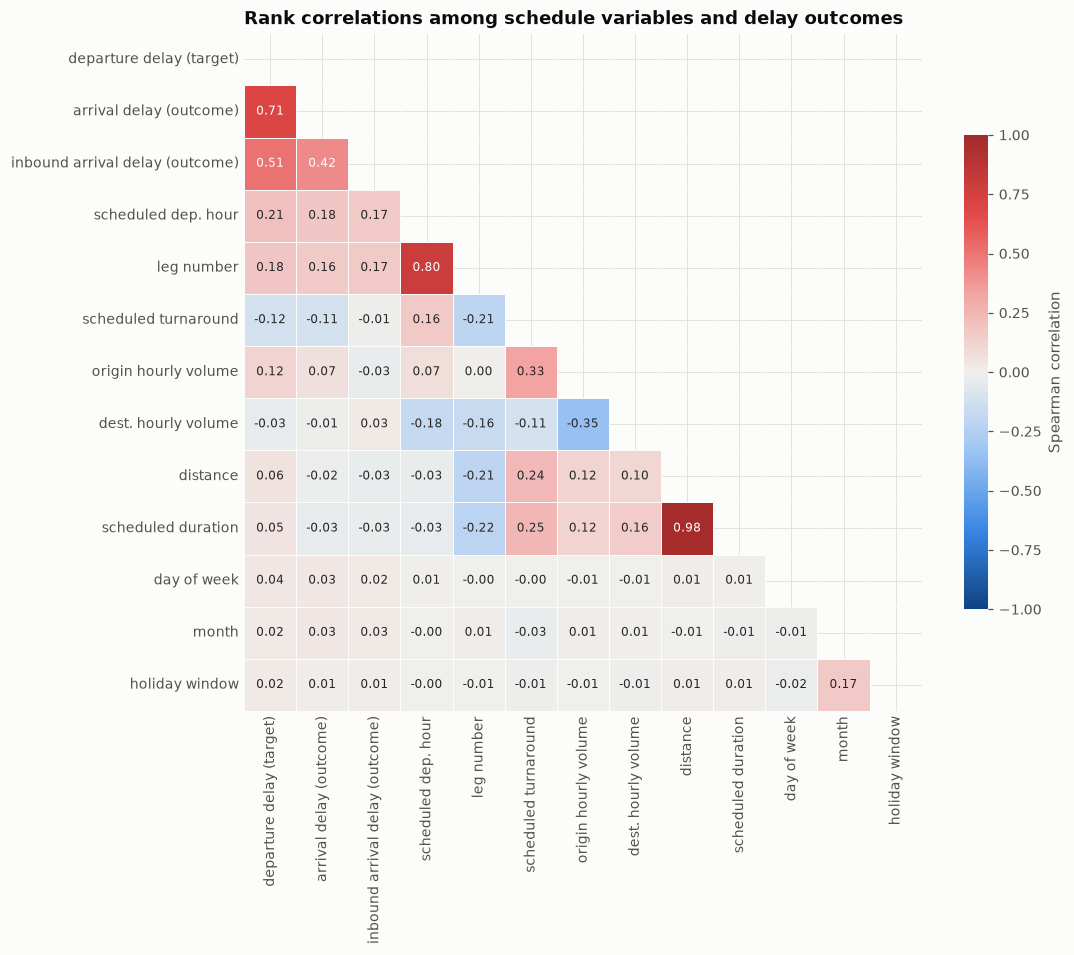

,departure delay (target)
arrival delay (outcome),0.707
inbound arrival delay (outcome),0.511
scheduled dep. hour,0.207
leg number,0.180
scheduled turnaround,-0.124
origin hourly volume,0.122
distance,0.061
scheduled duration,0.051
day of week,0.037
dest. hourly volume,-0.031


In [34]:
corr_cols = {
    "DEP_DELAY": "departure delay (target)", "ARR_DELAY": "arrival delay (outcome)",
    "prev_arr_delay": "inbound arrival delay (outcome)", "dep_hour": "scheduled dep. hour",
    "leg_num": "leg number", "sched_turn_min": "scheduled turnaround", "origin_hour_deps": "origin hourly volume",
    "dest_hour_arrs": "dest. hourly volume", "DISTANCE": "distance", "CRS_ELAPSED_TIME": "scheduled duration",
    "DAY_OF_WEEK": "day of week", "MONTH": "month", "holiday_window": "holiday window",
}
corr_sample = dep[list(corr_cols)].sample(n=300_000, random_state=SEED).astype("float64").rename(columns=corr_cols)
corr = corr_sample.corr(method="spearman")

fig, ax = plt.subplots(figsize=(10, 8))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap=viz.DIVERGING, vmin=-1, vmax=1, center=0, annot=True, fmt=".2f",
            annot_kws={"size": 8}, linewidths=0.6, linecolor=viz.SURFACE, square=True,
            cbar_kws={"label": "Spearman correlation", "shrink": 0.7}, ax=ax)
ax.set_title("Rank correlations among schedule variables and delay outcomes")
ax.tick_params(length=0)
viz.save(fig, "eq6_correlations", FIG_DIR)
plt.show()
corr["departure delay (target)"].drop("departure delay (target)").sort_values(key=abs, ascending=False).round(3).to_frame()

**Interpretation.**
* **Scheduled hour (0.21)** and **leg number (0.18)** are the strongest schedule-based correlates of departure delay. They are also strongly correlated with each other (0.80), because an aircraft's fourth flight is usually in the afternoon. A model needs both, or a way to separate them; the rotation persistence chart above shows the leg effect is real beyond time of day.
* **Turnaround and congestion:** longer scheduled turnarounds go with fewer delays (-0.12), as more slack absorbs inbound delay. Busier departure hours at the origin go with more (0.12).
* **Redundant variables:** distance and scheduled duration are nearly identical (0.98), so the model uses only distance.
* **Leakage:**
  * The strongest correlations belong to **outcomes**: arrival delay (0.71) and the inbound flight's arrival delay (0.51). Neither is known two hours before departure in general.
  * The inbound delay is used only in the restricted form allowed by our leakage rule (previous leg landed at least 2 hours before departure).
  * Together with the impossible-turnaround finding in Section 1.8, this is the main leakage risk the model has to avoid.
* **Monotone vs. non-monotone effects:** month barely correlates with delay (0.02), even though EQ2 showed strong seasonality. Spearman only detects monotone relationships, and the seasonal pattern goes up and down. Categorical or binned features handle that better than a raw month number.

## 2.8 EDA takeaways

1. **Delay is common but skewed.** 21.7% of departures leave 15+ minutes late, yet the median flight leaves early, and a heavy tail of multi-hour delays dominates averages. We use rates, medians and capped averages.
2. **Time is the dominant pattern.** Risk climbs through the day (about 8% at 6 a.m. to over 40% on summer evenings) and peaks in June-July and December. Specific bad days (early-January storms, the November disruptions) are clear anomalies.
3. **Carriers and airports differ in frequency, severity and cancellations.** Frontier is late most often and Hawaiian least, while regional carriers trade delays for cancellations. Busy hubs (DFW, DEN, ORD) run late, but size alone is a weak predictor across all airports.
4. **Late-arriving aircraft is the largest delay cause (39%)**, ahead of carrier (32%), NAS (22%) and weather (6%). It reaches half of all delay minutes at Southwest, PSA and Frontier. This is the category Q1 and Q3 try to trace back to where the delay started.
5. **Delay propagates.** About half of a large first-leg delay is still there on the next leg, and a quarter or more by the fifth. When the inbound aircraft arrives an hour late, the next departure is late 89% of the time.
6. **The rotation data can mislead a model.** Impossible recorded turnarounds reflect day-of aircraft swaps and are 55-95% delayed. Any feature built from them must be guarded, which is what Section 3 does.

# 3. Preliminary modeling

## 3.1 Goal and setup

* **Question (Q2):** will a flight depart 15 or more minutes late? The prediction is made **two hours before its scheduled departure**, early enough for an airline to act (swap an aircraft, warn passengers, add a crew).
* **Target:** `DEP_DEL15` (1 = departed 15+ minutes late). **Population:** every flight that departed. Cancelled flights have no departure delay; diverted flights did depart and are kept.
* **Allowed information:** the published schedule, the calendar, the aircraft's planned sequence of flights, and the previous leg's arrival delay **only if that leg had landed by the two-hour cutoff**. Otherwise the model falls back on the scheduled turnaround alone. Nothing about the flight's own outcome, and no actual (as opposed to scheduled) times, are used.
* **Metric:** about one flight in five is delayed, so accuracy is misleading (always predicting "on time" is about 78% accurate and useless). The headline metric is **PR-AUC** (average precision, the area under the precision-recall curve). We also report precision and recall at a threshold chosen on the validation month, with ROC-AUC as a secondary measure.
* **Models now:** two baselines and logistic regression with two feature sets. **Gradient boosting** is planned for the final.

## 3.2 Feature sets and a leakage audit

Two logistic regression variants test whether the rotation information is worth having. A short audit confirms that no forbidden column is among the inputs.

In [35]:
SCHEDULE_ONEHOT = ["OP_UNIQUE_CARRIER", "DAY_OF_WEEK", "dep_hour", "arr_hour", "holiday_window"]
SCHEDULE_RATES = ["ORIGIN", "DEST", "route", "carrier_origin"]     # high-cardinality -> target encoding
SCHEDULE_NUMERIC = ["log_distance", "log_origin_hour_deps", "log_dest_hour_arrs"]
ROTATION_ONEHOT = ["leg_bucket", "turn_bucket", "prev_landed_by_cutoff"]
ROTATION_NUMERIC = ["prev_delay_at_cutoff"]
ALL_INPUTS = SCHEDULE_ONEHOT + SCHEDULE_RATES + SCHEDULE_NUMERIC + ROTATION_ONEHOT + ROTATION_NUMERIC

FORBIDDEN = (["DEP_DELAY", "DEP_DELAY_NEW", "DEP_DEL15", "ARR_DELAY", "ARR_DEL15", "CANCELLED",
              "CANCELLATION_CODE", "DIVERTED", "actual_dep", "leg_num", "n_legs", "chain_break",
              "sched_turn_min", "prev_arr_delay", "irregular_sequence", "MONTH"] + clean.CAUSE_COLS)
leaks = sorted(set(ALL_INPUTS) & set(FORBIDDEN))
assert not leaks, f"Forbidden columns in the inputs: {leaks}"
print(f"Leakage audit passed: none of the {len(FORBIDDEN)} outcome or actual-time columns is an input.")
print(f"Schedule-only model: {len(SCHEDULE_ONEHOT + SCHEDULE_RATES + SCHEDULE_NUMERIC)} input columns; "
      f"with rotation features: {len(ALL_INPUTS)}.")

Leakage audit passed: none of the 21 outcome or actual-time columns is an input.
Schedule-only model: 12 input columns; with rotation features: 16.


## 3.3 Time-based split

| Set | Months | Used for |
|---|---|---|
| Train | Jan-Sep | fitting, minus the irregular sequences explained in Section 1.9 |
| Validation | Oct | choosing the regularization strength and the decision threshold |
| Test | Nov-Dec | final scores, looked at once |

A random split would let the model learn from flights on the same stormy afternoon it is tested on. Splitting by time mimics real use: train on the past, predict the future. One consequence is that **month cannot be a feature**, because November and December never appear in training.

In [36]:
model_df = df.loc[df.CANCELLED == 0, ALL_INPUTS + ["MONTH", "irregular_sequence", "DEP_DEL15"]].copy()
model_df["y"] = model_df.DEP_DEL15.astype(int)

train_months = model_df.MONTH <= 9
train = model_df[train_months & ~model_df.irregular_sequence]
val = model_df[model_df.MONTH == 10]
test = model_df[model_df.MONTH >= 11]

split = pd.DataFrame({
    "months": ["Jan-Sep", "Oct", "Nov-Dec"],
    "flights": [len(train), len(val), len(test)],
    "% delayed (positives)": [train.y.mean() * 100, val.y.mean() * 100, test.y.mean() * 100],
}, index=["train", "validation", "test"]).round(1)
print(f"Irregular sequences left out of training: {(train_months & model_df.irregular_sequence).sum():,} "
      f"({(train_months & model_df.irregular_sequence).mean() / train_months.mean():.1%} of Jan-Sep flights)")
split

Irregular sequences left out of training: 166,539 (3.2% of Jan-Sep flights)


,months,flights,% delayed (positives)
train,Jan-Sep,4999906,20.0
validation,Oct,602640,19.6
test,Nov-Dec,1129658,23.4


## 3.4 Baselines

A model is only useful if it beats something simple:

1. **Always "on time".** It predicts the majority class for every flight. Its accuracy looks high (about 77-80%), but it catches no delays. Its PR-AUC equals the share of delayed flights, which is the floor.
2. **Historical delay rate.** A lookup table: the share of *training* flights by the same carrier, from the same origin, in the same departure hour that left 15+ minutes late. Small groups are shrunk toward the overall rate (`features.historical_rate`), and combinations never seen in training get the overall rate. No machine learning, just history.

Each model's decision threshold is the one that maximizes F1 on the **validation** month. It is then applied unchanged to the test months.

In [37]:
results_val, results_test, test_scores, thresholds = {}, {}, {}, {}

def record(name, val_scores, test_score_values, threshold=None):
    """Score a model; the threshold is tuned on validation unless one is given."""
    if threshold is None:
        threshold = evaluate.best_f1_threshold(val.y, val_scores)
    thresholds[name] = threshold
    results_val[name] = evaluate.evaluate(val.y, val_scores, threshold)
    results_test[name] = evaluate.evaluate(test.y, test_score_values, threshold)
    test_scores[name] = np.asarray(test_score_values, dtype=float)

# 1. Always "on time": a constant score of 0 with threshold 0.5, so no flight is ever flagged.
record("Always on time", np.zeros(len(val)), np.zeros(len(test)), threshold=0.5)

# 2. Historical delay rate of carrier x origin x departure hour, from training months only.
HIST_KEYS = ["OP_UNIQUE_CARRIER", "ORIGIN", "dep_hour"]
record("Historical rate",
       features.historical_rate(train, val, HIST_KEYS, target="y"),
       features.historical_rate(train, test, HIST_KEYS, target="y"))

evaluate.comparison_table(results_test).round(3)

,PR-AUC,ROC-AUC,threshold,precision,recall,F1,accuracy,share flagged
Always on time,0.234,0.500,0.500,0.000,0.000,0.000,0.766,0.000
Historical rate,0.351,0.656,0.206,0.329,0.584,0.421,0.624,0.416


## 3.5 Logistic regression

**Why logistic regression first.** It is the standard interpretable classifier for a yes/no outcome. Each coefficient says how a feature shifts the log-odds of a delay, it trains in seconds on 5 million rows, and it is the first model we said we would try in our proposal, before gradient boosting.

**Pipeline** (built with scikit-learn so that every transformation is learned from the training months only):
* **One-hot encoding** for low-cardinality categories (carrier, weekday, hour, rotation buckets).
* **Target encoding** for the high-cardinality ones (about 350 origins and destinations, about 6,700 routes, about 1,000 carrier-airport pairs). Each category is replaced by its smoothed training delay rate. `TargetEncoder` uses internal cross-fitting, so a training flight's own label never feeds its own encoding.
* **Standardization** of numeric and encoded columns, so coefficients are comparable (per standard deviation).
* **L2-regularized logistic regression.** We check the regularization strength `C` on the validation month.

In [38]:
def make_logistic(onehot, rates, numeric, C=1.0):
    preprocess = ColumnTransformer([
        ("onehot", OneHotEncoder(handle_unknown="ignore"), onehot),
        ("rate", make_pipeline(features.make_target_encoder(SEED), StandardScaler()), rates),
        ("num", StandardScaler(), numeric),
    ])
    return make_pipeline(preprocess, LogisticRegression(C=C, max_iter=1000))

def fit_logistic(onehot, rates, numeric, C=1.0, train_rows=None):
    train_rows = train if train_rows is None else train_rows
    cols = onehot + rates + numeric
    model = make_logistic(onehot, rates, numeric, C)
    start = time.time()
    model.fit(train_rows[cols], train_rows.y)
    val_scores = model.predict_proba(val[cols])[:, 1]
    print(f"  C={C:<5} fitted in {time.time() - start:5.1f} s ({model[-1].n_iter_[0]} iterations); "
          f"validation PR-AUC {evaluate.evaluate(val.y, val_scores, 0.5)['PR-AUC']:.4f}")
    return model, cols, val_scores

SCHEDULE = (SCHEDULE_ONEHOT, SCHEDULE_RATES, SCHEDULE_NUMERIC)
WITH_ROTATION = (SCHEDULE_ONEHOT + ROTATION_ONEHOT, SCHEDULE_RATES, SCHEDULE_NUMERIC + ROTATION_NUMERIC)

print("Logistic regression, schedule features only:")
lr_schedule, cols_schedule, val_schedule = fit_logistic(*SCHEDULE)

print("Logistic regression, schedule + rotation features, three regularization strengths:")
c_search = {C: fit_logistic(*WITH_ROTATION, C=C) for C in [0.01, 0.1, 1.0]}
best_C = max(c_search, key=lambda C: evaluate.evaluate(val.y, c_search[C][2], 0.5)["PR-AUC"])
lr_rotation, cols_rotation, val_rotation = c_search[best_C]
print(f"Chosen C = {best_C}")

record("LR: schedule", val_schedule, lr_schedule.predict_proba(test[cols_schedule])[:, 1])
record("LR: schedule + rotation", val_rotation, lr_rotation.predict_proba(test[cols_rotation])[:, 1])

Logistic regression, schedule features only:


  C=1.0   fitted in  11.3 s (52 iterations); validation PR-AUC 0.3352
Logistic regression, schedule + rotation features, three regularization strengths:


  C=0.01  fitted in  12.3 s (46 iterations); validation PR-AUC 0.3546


  C=0.1   fitted in  13.2 s (51 iterations); validation PR-AUC 0.3546


  C=1.0   fitted in  13.0 s (51 iterations); validation PR-AUC 0.3546


Chosen C = 0.1


**What we see.**
* **Rotation features help on validation:** they raise October PR-AUC from 0.335 to 0.355.
* **Regularization doesn't matter here:** `C` from 0.01 to 1 changes validation PR-AUC only in the fifth decimal. With 5 million training rows and about 90 coefficients there is little overfitting for regularization to control, so we keep the (essentially tied) best value and do not search further.
* **Fitting is fast:** each fit takes about 15 seconds, which leaves room for richer models in the final.

## 3.6 Evaluation on the test months (Nov-Dec)

In [39]:
table = evaluate.comparison_table(results_test)
table.insert(1, "PR-AUC (validation)", [results_val[m]["PR-AUC"] for m in table.index])

def top_decile_precision(y, scores):
    """Share of the 10% highest-risk flights that actually left 15+ min late."""
    cutoff = np.quantile(scores, 0.9)
    return np.asarray(y)[scores >= cutoff].mean() if np.unique(scores).size > 1 else np.nan

table["precision in top 10%"] = [top_decile_precision(test.y, test_scores[m]) for m in table.index]
table.round(3)

,PR-AUC,PR-AUC (validation),ROC-AUC,threshold,precision,recall,F1,accuracy,share flagged,precision in top 10%
Always on time,0.234,0.196,0.500,0.500,0.000,0.000,0.000,0.766,0.000,NaN
Historical rate,0.351,0.333,0.656,0.206,0.329,0.584,0.421,0.624,0.416,0.418
LR: schedule,0.361,0.335,0.663,0.215,0.335,0.593,0.428,0.629,0.415,0.432
LR: schedule + rotation,0.379,0.355,0.676,0.216,0.346,0.605,0.441,0.640,0.409,0.456


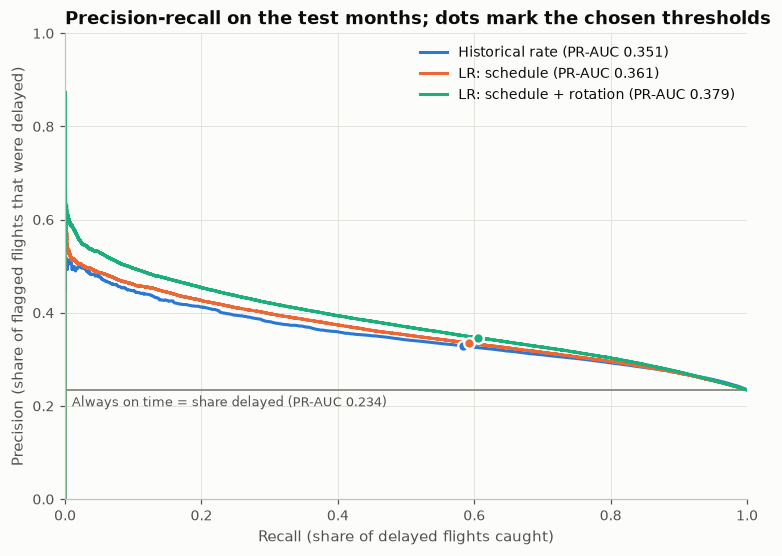

In [40]:
fig, ax = plt.subplots(figsize=(8, 5.5))
prevalence = test.y.mean()
ax.axhline(prevalence, color=viz.MUTED, linewidth=1.2)
ax.text(0.01, prevalence - 0.035, f"Always on time = share delayed (PR-AUC {prevalence:.3f})", ha="left",
        fontsize=8.5, color=viz.INK_2)
for (name, color) in zip(["Historical rate", "LR: schedule", "LR: schedule + rotation"], viz.CATEGORICAL[:3]):
    precision, recall, _ = precision_recall_curve(test.y, test_scores[name])
    ax.plot(recall[:-1], precision[:-1], color=color, linewidth=2, label=f"{name} (PR-AUC {results_test[name]['PR-AUC']:.3f})")
    chosen = results_test[name]
    ax.scatter(chosen["recall"], chosen["precision"], s=48, color=color, edgecolor=viz.SURFACE, linewidth=1.5, zorder=4)
ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="Recall (share of delayed flights caught)",
       ylabel="Precision (share of flagged flights that were delayed)",
       title="Precision-recall on the test months; dots mark the chosen thresholds")
ax.legend(loc="upper right")
viz.save(fig, "model_pr_curves", FIG_DIR)
plt.show()

In [41]:
best = "LR: schedule + rotation"
pred = (test_scores[best] >= thresholds[best]).astype(int)
cm = pd.DataFrame(confusion_matrix(test.y, pred),
                  index=["actually on time", "actually delayed"], columns=["predicted on time", "predicted delayed"])
cm

,predicted on time,predicted delayed
actually on time,562840,302117
actually delayed,104523,160178


**Interpretation.**
* **Baselines:** "always on time" is 76.6% accurate on the test months and catches **zero** delays. This is why accuracy is not our metric. Its PR-AUC of 0.234 is simply the share of delayed flights, the floor any useful model must beat.
* **Logistic regression with rotation features** reaches **PR-AUC 0.379**, against 0.351 for the historical lookup table and 0.361 for logistic regression on schedule features alone.
  * At the threshold chosen on October data, it flags 41% of flights. **35% of flagged flights are actually delayed** (precision, versus 23% by chance), and it catches **61% of all delays** (recall).
  * Among the 10% of flights it ranks riskiest, **46%** leave late, double the base rate.
* **Where the gains come from:** the logistic regression's gain over the lookup table is modest on schedule features alone (+0.010). The aircraft-rotation features add nearly twice as much again (+0.018), so rebuilding the rotations helps with prediction too, not just with Q3.
* **Generalization:** validation (October) and test (Nov-Dec) PR-AUCs are close, so the model is not overfitting. What holds it back is how little is known two hours ahead.

**Limitations.** A PR-AUC under 0.4 means the schedule only gets us part of the way. Much of what makes a given flight late (a thunderstorm, a mechanical problem, the state of the airport that afternoon) is not in the schedule at all. Our next steps try to add some of that missing information.

## 3.7 What the model learned

Standardized coefficients of the chosen model. Positive values raise the predicted delay risk and negative values lower it. One-hot coefficients compare each category with the others in its group, and target-encoded and numeric coefficients are per one standard deviation. This is a preview of the feature-importance ranking planned for the final, where permutation importance on the gradient-boosting model will complement it.

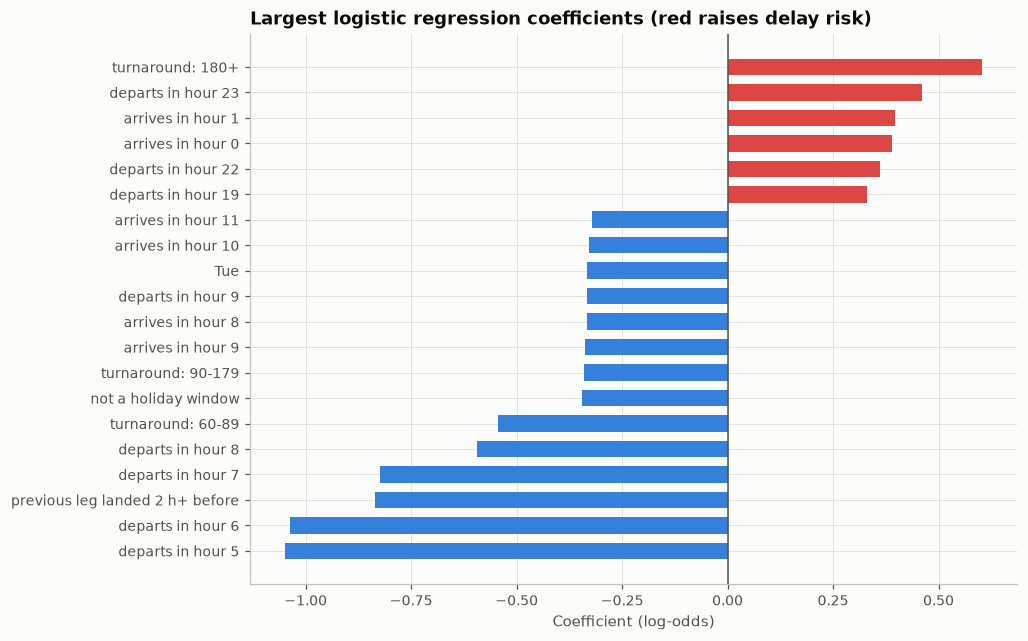

,coefficient
departs in hour 5,-1.049
departs in hour 6,-1.038
previous leg landed 2 h+ before,-0.836
departs in hour 7,-0.824
turnaround: 180+,0.604
departs in hour 8,-0.594
turnaround: 60-89,-0.543
departs in hour 23,0.461
arrives in hour 1,0.397
arrives in hour 0,0.390


In [42]:
def readable(name):
    """Turn encoder output names such as 'onehot__dep_hour_6' into plain words."""
    group, feature = name.split("__", 1)
    replacements = [
        ("dep_hour_", "departs in hour "), ("arr_hour_", "arrives in hour "),
        ("turn_bucket_", "turnaround: "), ("leg_bucket_", "leg of the day: "),
        ("prev_landed_by_cutoff_1", "previous leg landed 2 h+ before"),
        ("prev_landed_by_cutoff_0", "previous leg not landed 2 h before"),
        ("holiday_window_1", "holiday window"), ("holiday_window_0", "not a holiday window"),
        ("OP_UNIQUE_CARRIER_", "carrier "), ("prev_delay_at_cutoff", "previous leg's delay at cutoff"),
        ("log_origin_hour_deps", "origin hourly volume (log)"), ("log_dest_hour_arrs", "dest. hourly volume (log)"),
        ("log_distance", "distance (log)"),
    ]
    days = {f"DAY_OF_WEEK_{i}": d for i, d in enumerate(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], 1)}
    if feature in days:
        return days[feature]
    for old, new in replacements:
        if feature.startswith(old):
            return new + feature[len(old):]
    return f"historical delay rate: {feature}" if group == "rate" else feature

pretty = [readable(n) for n in lr_rotation[0].get_feature_names_out()]
coefs = pd.Series(lr_rotation[-1].coef_[0], index=pretty).sort_values(key=abs, ascending=False)
top = coefs.head(20).sort_values()

fig, ax = plt.subplots(figsize=(9, 6.5))
ax.barh(top.index, top, color=[viz.DIVERGING(0.85) if v > 0 else viz.DIVERGING(0.15) for v in top], height=0.65)
ax.axvline(0, color=viz.INK_2, linewidth=1)
ax.set(title="Largest logistic regression coefficients (red raises delay risk)", xlabel="Coefficient (log-odds)")
viz.save(fig, "model_coefficients", FIG_DIR)
plt.show()
coefs.head(20).round(3).to_frame("coefficient")

**Interpretation.**
* **Time of day dominates.** Departures between 5 and 8 a.m. carry the largest negative coefficients (lowest risk), and late-evening departures and after-midnight arrivals the largest positive ones. This matches the heatmap in EQ2.
* **Rotation features rank near the top.**
  * An aircraft whose previous flight had already landed two or more hours before departure is much less likely to leave late.
  * Medium ground times (60 to 179 minutes) lower risk relative to tight ones.
  * Long ground times of three hours or more *raise* it. One plausible reading is that these legs follow an aircraft or crew change and inherit their delays; we will check that in the final.
* **Calendar effects are smaller but visible:** Tuesday flights carry lower risk, and dates outside the holiday windows lower risk.

Because many features overlap (hour, leg number, turnaround), individual coefficients should be read as directions, not exact effect sizes. Permutation importance in the final will rank features more reliably.

## 3.8 Next steps before the final

1. **Gradient boosting.** Fit scikit-learn's `HistGradientBoostingClassifier` on the same split and features. It captures interactions logistic regression cannot (hour x airport x season, for example), which the EDA suggests matter. It will complete the planned comparison table (baseline, logistic regression, gradient boosting) and get a permutation feature-importance ranking.
2. **More information available at the two-hour cutoff, without leakage:**
   * **Airport state at the cutoff.** What share of the origin airport's departures in the previous hours left late. Same airport means the same local clock, so no time-zone issue.
   * **Status of the inbound aircraft at the cutoff** (departed, airborne, or not yet departed), using the time-zone offsets this notebook already recovers from the schedule. This goes beyond the current previous-leg rule, so we will agree on it as a team before using it.
3. **Weather.** Pull hourly Open-Meteo weather for the 25 to 30 busiest origin airports, aligned from UTC to local time. It serves both as model features and for the Q1 question of whether reported weather delay is understated (storm days vs. weather and NAS shares).
4. **Q3 decay curve.** Turn the persistence chart into a regression of later-leg delay on first-leg delay, controlling for time of day, carrier and scheduled turnaround. Report the headline number: a 30-minute first-leg delay produces *N* additional minutes across the rest of the day.
5. **Model checks:** probability calibration, a cost-based choice of threshold, performance month by month and on disrupted vs. normal days (the November anomaly), and a comparison with unguarded rotation features to measure how much the leakage guard matters.

# 4. Progress summary

This section is our written summary (1-2 pages) of the progress so far, the challenges we ran into, and our plans for the final.

## 4.1 Progress made

**Data wrangling.** We cleaned and checked all twelve months of the 2025 BTS on-time data: 7,001,619 scheduled flights from 14 carriers at 352 airports. The cleaned table is saved to `processed/flights_2025_clean.parquet`, so later work does not have to start from the raw CSVs again.
* Every missing value we found had a reason behind it. Departure delay is blank only for cancelled flights, arrival delay only for cancelled or diverted flights (plus one odd Republic record), and the cause columns only when a flight arrived less than 15 minutes late. We filled cause minutes with 0 only where 0 is the true value.
* We converted the text dates and float flags to proper types and turned the local `HHMM` times into real timestamps, including 227,724 flights that land the next day.
* Instead of deleting outliers with the IQR rule, which would have removed 60% of the delayed flights, we flagged extreme or contradictory records and kept them.
* We rebuilt each aircraft's flights for the day from its tail number: 1.73 million aircraft-days, with only 0.49% of legs not lining up with the flight before.

**Exploratory data analysis.** We answered six exploratory questions with 11 figures. The main things we learned:
* 21.7% of departures leave 15+ minutes late, but the median flight actually leaves 2 minutes early. A small number of very long delays pull the average up.
* Time matters most. Delay risk goes from about 8% at 6 a.m. to over 40% on summer evenings. July and December are the worst months and September is the best.
* Late-arriving aircraft is the biggest delay cause at 39% of delay minutes, ahead of carrier (32%), NAS (22%) and weather (6%). This is our first answer to Q1.
* Delay carries over from flight to flight. About half of a big first-flight delay is still there on the next flight, and aircraft that start 2+ hours late are still 49 minutes behind on-time starters by their fifth flight. This is our first evidence for Q3.

**Preliminary modeling.** For Q2 we predict whether a flight will leave 15+ minutes late, two hours before its scheduled departure. We trained on January to September, tuned on October, and tested once on November and December. PR-AUC is our main metric because only about 1 in 5 flights is delayed. For the previous flight's arrival delay we used this rule: the model only sees it if that flight had landed at least two hours before departure. Otherwise it only gets the scheduled turnaround.

| Model (test months, 23.4% delayed) | PR-AUC | Precision | Recall |
|---|---|---|---|
| Always "on time" | 0.234 | n/a | 0.00 |
| Historical delay rate (carrier x origin x hour) | 0.351 | 0.33 | 0.58 |
| Logistic regression, schedule features | 0.361 | 0.34 | 0.59 |
| Logistic regression, + rotation features | 0.379 | 0.35 | 0.61 |

The rotation features (which flight of the day it is, the scheduled ground time, and the previous flight's delay when it is allowed) gave the biggest improvement. Among the 10% of flights the model ranks as most risky, 46% actually left late, about twice the normal rate. A PR-AUC under 0.4 also tells us that a lot of delay cannot be predicted from the schedule alone.

## 4.2 Challenges and how we handled them

* **No time zones.** BTS gives local times without a time zone, so we could not directly tell when an overnight or cross-country flight landed. We worked out each flight's clock difference from its own schedule (arrival = departure + scheduled duration + time difference) and added a fix for the Honolulu-Guam flights that cross the date line.
* **Leakage from aircraft swaps.** BTS records the plane that actually flew. When an airline swaps planes during the day, some flights end up with turnarounds that are impossible on paper, and 95% of those flights left late. Using them as features would basically give the model the answer, so we marked these flights, hid their turnaround from the model, and left them out of training.
* **Skewed delays.** The IQR rule did not fit this data, so we used flags based on what makes sense for flights and capped very long delays at 12 hours when computing averages.
* **Size and messy files.** Reading 7 million rows with compact types kept the table at about 575 MB. The file names were inconsistent (`JUNE`, `.csv.csv`), so we read the month from each file name and checked it against the data inside.

## 4.3 Plans for the final

1. Gradient boosting (`HistGradientBoostingClassifier`) with permutation feature importance, to compare against logistic regression.
2. New features that are known at the two-hour cutoff: how delayed the origin airport has been in the previous hours, and possibly the inbound aircraft's status. We still need to agree on the second one as a team so it fits our leakage rules.
3. Hourly weather for the 25 to 30 busiest airports, both as model features and to check whether weather delay is under-reported (Q1).
4. A decay curve for Q3 that gives one main number: how many extra minutes a 30-minute first-flight delay causes over the rest of the aircraft's day.
5. More model checks: calibration, results month by month and on bad days, and measuring how much the leakage guard matters.

In [43]:
print(f"Notebook ran top to bottom in {(time.time() - NOTEBOOK_START) / 60:.1f} minutes.")

Notebook ran top to bottom in 1.6 minutes.
